# Partea a 4-a. Transformer Contrastive infoNCE

In [1]:
import pandas as pd
import re
from sklearn.preprocessing import StandardScaler, LabelEncoder
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
import torch.nn as nn
from transformers import AutoModel
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import f1_score, accuracy_score
import torch
import numpy as np
import random

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from collections import Counter
import unicodedata
from torch.utils.data import Sampler
import torch.nn.functional as F

import matplotlib
# matplotlib.use("Agg")  # servere fara GUI
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib.pyplot as plt
import os
import json


Variabile globale:

In [2]:
OUTPUT_DIR = "outputs_contrastive_1"
MODEL_PATH = "best_model_contrastive.pt"

EPOCHS = 15
LR = 2e-5
WEIGHT_DECAY = 0.01
MAX_LEN = 512 # pana acum am testat cu 512 dar e dezastruos pe top 40 moldova , 512 e cel mai bun lasa asa 
CONTRASTIVE_WEIGHT = 0.7 # prea mare pastrez 0.3 pentru ca si asa e un loss urias, vezi ca rularea curenta e cu 0.7
TEMPERATURE = 0.07 # testeaza cu 0.1
OVERLAP = 0.3 # 0.1 e cam slabut as zice sper sa mearga un pic mai mare

- tokenizer si device (doar aici!!)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")


- daca exista directorul nu il mai facem , dar sa fim siguri rulam si aici

In [4]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

Si aici vom folosi functii de clean , de asemenea, set seed functioneaza doar daca raman aceiasi paramterii la model inclusiv acelasi numar de epoci.
- Trebuie cautat daca am weights diferite pe masini diferite

In [5]:
# FUNCTII UTILE le definim sus
def drop_columns(df, columns_to_drop):
    return df.drop(columns=columns_to_drop)

# avem o problema la moldova
# diacriticele aparent nu sunt unicode?
def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = unicodedata.normalize("NFC", text)

    # remove combining chars, deci t de la tap nu va mai avea caciulita sepaarata va fi un singur char
    text = ''.join(c for c in text if not unicodedata.combining(c))

    text = text.replace("„", '"').replace("”", '"')
    text = text.replace("’", "'")

    # remove control chars
    text = ''.join(c for c in text if unicodedata.category(c)[0] != 'C')

    text = text.replace("\n", " ")
    text = text.replace('""', '"')
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def count_unk(texts, tokenizer, n=100):
    total_unk = 0
    total_tokens = 0

    for t in texts[:n]:
        enc = tokenizer(
            t,
            truncation=True,
            max_length=MAX_LEN
        )

        input_ids = enc["input_ids"]
        total_tokens += len(input_ids)

        unk_id = tokenizer.unk_token_id
        total_unk += sum(1 for x in input_ids if x == unk_id)

    return total_unk / total_tokens


def count_unk_absolute(texts, tokenizer, n=100):
    total_unk = 0
    for t in texts[:n]:
        enc = tokenizer(t, truncation=True, max_length=MAX_LEN)
        unk_id = tokenizer.unk_token_id
        total_unk += sum(1 for x in enc["input_ids"] if x == unk_id)
    return total_unk


def count_combining(texts, n=1000):
    count = 0
    for t in texts[:n]:
        if any(unicodedata.combining(c) for c in t):
            count += 1
    return count


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

### Checkpoint Implementare

1. Contrastive Dataset
   - in lucrarea lui Huerta (generating user embeddings with transformers) se foloseste infoNCE ca functie de loss
   - ideea lor este sa faca 2 matrice , produs scalar, normalizare , aplicat info nce minimizat info nce, care se uita la diagonala principala si trebuie sa aiba valoare cea mai mare la prima pozitie (a autorului pozitiv)
   - pentru fiecare autor vom tine o lista de ferestre de 512 tokeni (pt bert) si de aici vom extage primele 400 pentru ca vrem 200 de batch-uri x 2 texte/autor
2. Din pacate depinde de cate texte avem per autor si cate ferestre de 512 tokeni putem scoate. Am incercat si cu alte valori la max len si overlap dar astea au fost cele mai bune

Pas 1: pastram Author Dataset pentru setul de test pentru ca acolo nu mai avem perechi de autori ci doar identificam direct dupa document

In [6]:
class AuthorDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=MAX_LEN):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      encoded['input_ids'].squeeze(0),
            'attention_mask': encoded['attention_mask'].squeeze(0),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

**Pas 2**: Pentru validare si train ne trebuie o functie care mapeaza autorii la 2 ferestre (a se vedea matricea X si X_t). Fiecare text al unui autor este separat in ferestre de overlap = 0.1 (10%) salvez aceste ferestre intr-o lista. Pare redundant dar pentru robustete ma folosesc de tokenizer si decodez ca sa le am ca text direct nu ca encoding. `prepare_texts_wit-windows` tine cont de toate ferestrele si toate labels , fara a fi nevoie sa folosesc dicitionar

In [7]:
# definim o functie in care mapam fiecare autor la ferestre de 512 tokeni
def split_into_windows(text, tokenizer, max_length=MAX_LEN, overlap=OVERLAP):
    # permitem si overlap
    # returnam o lista de stringuri (ferestre)
    stride = int(max_length * (1-overlap)) # cu asta parcurg ~ step
    # scoatem tokens cu tokenizer
    tokens = tokenizer(
        text,
        truncation=False, # pt windows
        add_special_tokens=False,
        return_tensors='pt' # pytorch tensors buni pt cuda
    )
    input_ids = tokens['input_ids'][0]

    # daca e mai mic ca max_len il returnam direct asa
    if len(input_ids) <= max_length:
        return [text]
    # impartim in ferestre
    windows = []
    for start in range(0, len(input_ids), stride):
        # iau end
        end = min(len(input_ids), start + max_length)
        window_ids = input_ids[start:end]
        # decodam pt compatibilitate cu ce o sa faca bert
        window_text = tokenizer.decode(window_ids, skip_special_tokens=True)
        windows.append(window_text)
        if end == len(input_ids):
            break

    return windows


def prepare_texts_with_windows(texts, labels, tokenizer, max_length=MAX_LEN,overlap=OVERLAP):
    # acum mapam autori -> [win1, win2 ...]
    # returnam liste extinse de texte si etichete
    all_texts = []
    all_labels = []

    for text, label in zip(texts, labels):
        windows = split_into_windows(text, tokenizer, max_length, overlap)
        all_texts.extend(windows)
        all_labels.extend([label] * len(windows))

    counts = Counter(all_labels)
    print(f"Texte originale: {len(texts)}")
    print(f"Ferestre totale: {len(all_texts)}")
    for label, count in sorted(counts.items()):
        print(f"  autor {label}: {count} ferestre")

    return all_texts, all_labels

Pas 3: `ContrastiveDataset` returneaza garantat o pereche de texte pt acelasi autor (sau ferestre). Ca sa putem sa scoatem de la toti autorii in `get_item` folosim un index pentru label (faptul ca luam pe top 20 si top 40 ajuta pentru ca traducem direct eticheta autorului in index)

Traducere: Eu vreau asa: `[(A), (B), (C), ...]` unde fiecare element este de forma: `(text1_autor, text2_autor, autor)`. Deci 1 exemplu este : 2 texte (ferestre de text) din acelasi autor + label(autor).

Datasetul: `batch = [dataset[i], dataset[j], dataset[k]]` iar DataLoader poate sa ia : (A_pair1), (A_pair2), (A_pair3) , dar nu vrem asta ci vrem perechi din autori diferiti.
Prima varianta ar fi sa construim manual batch-urile: Pt fiecare autor: <br>
A → [pair1, pair2, pair3] <br>
B → [pair1, pair2, pair3] <br>
C → [pair1, pair2, pair3] <br>

O sa avem: <br>
batch0 = [A_pair1, B_pair1, C_pair1] <br>
batch1 = [A_pair2, B_pair2, C_pair2] <br>
batch2 = [A_pair3, B_pair3, C_pair3] <br>

Si datasetul devine: `dataset = [batch0, batch1, batch2]`, deci cand extrag `dataset[i]` am deja un batch.

Ne asiguram ca Dataset nu returneaza mereu aceasi pereche cu random seed generat la fiecare epoca `seed + epoch`


In [8]:
"""
initial am asa: texts = ["...", "...", "..."]
labels = [0, 0, 1, 2, 1, ...]

1 text = 1 exemplu
eu vreau: (text1, text2, label) = exemplu

Pas1: grupam pe autori Autor 0 = [win1, win2, ..]
"""
class ContrastiveAuthorDataset(Dataset):

  def __init__(self, texts, labels, batches_per_epoch=None, epoch=0, seed=42):

    # ne asiguram ca avem acelasi shuffle pe epoca
    rng = random.Random(seed + epoch)

    # grupam ferestrele pe autori
    # ne vom folosi de un dictionar pt asta
    # author_texts = { autor: [lista texte] }
    author_texts = {}
    for text, label in zip(texts, labels):
      # daca nu il am deja in dex il instantiez
      if label not in author_texts:
        author_texts[label] = []
      author_texts[label].append(text)

    #ok dar daca nu am macar 2 ferestre la un autor nu il pot pune pe ala
    self.valid_authors = sorted([
        a for a, t in author_texts.items() if len(t) >= 2
    ])

    # ok acum putem sa cream perechile pe autor
    # 1. copiezi lista de texte
    # 2. faci shuffle
    # 3. creezi perechi consecutive:
    #   (t1,t2), (t3,t4)
    # salvam ca:
    # author_pairs = {autor: [(t1,t2), (t3,t4)}

    # dar trebuie calculat minimul de ferestre
    min_windows = min(
        len(author_texts[a]) for a in self.valid_authors
    )

    # putem configura doar un anumit nr de perechi per autor
    # conditionat de numarul minim de ferestre
    # pe care il impartim la 2 ca luam perechi
    max_pairs = min_windows // 2

    if batches_per_epoch is None:
      n_pairs = max_pairs
    else:
      n_pairs = min(batches_per_epoch, max_pairs)

    # nu stiu cat de relevanta e asta sincer:
    # n_pairs = min(batches_per_epoch, max_perechi)
    print(f"Autori: {len(self.valid_authors)}")
    print(f"Min ferestre per autor: {min_windows}")
    print(f"Perechi per autor: {max_pairs}")

    # ok acum ca stim max_pairs trebuie sa generam fix atatea per autor
    # pentru fiecare index k :
    #   batch_k = []
    # pt fiecare autor:
    # iau perechea k  si adaug in batch
    self.pairs = []       #(text1, text2)
    self.pair_labels = [] # (label)

    for author in self.valid_authors:
      windows = author_texts[author].copy()
      rng.shuffle(windows) # riksyy
      # acum iau perechile consecutive dupa shuffle
      for i in range(0, n_pairs * 2, 2): # daca e impar min_windows??
        self.pairs.append((windows[i], windows[i+1]))
        self.pair_labels.append(author)

    print(f"Total perechi: {len(self.pairs)}")


  def __len__(self):
    return len(self.pairs)


  def __getitem__(self, index):
    # scoatem de la index exemplul
    text1, text2 = self.pairs[index]
    label = self.pair_labels[index]

    return {
        'text1': text1,
        'text2': text2,
        'label': label
    }

Deocamdata ave lista de perechi
Dar vrem batch!
Pas 4: Sampler <br>
Ca sa putem garanta ca un autor nu apare de 2 ori in batch tinem o lista de indecsi in care apare fiecare autor.
Cum transform: `[(A), (A), (B), (C), (B)]` in `batch = [A, B, C]`

In [9]:
class UniqueAuthorBatchSampler(Sampler):
  def __init__(self, dataset, seed=42):
    # grupam indici pe autor
    #   author_indices = {}

    # pentru fiecare index i:
    #   label = pair_labels[i]
    #   author_indices[label].append(i)

    # obtinem: A = [0,1], B = [2,4], C = [3,5]
    self.seed = seed

    self.author_indices = {}
    for idx, label in enumerate(dataset.pair_labels):
      if label not in self.author_indices:
        self.author_indices[label] = []
      self.author_indices[label].append(idx)

    # ok cate batch-uri putem avea?
    # as zice nr minim de exemple autor
    self.authors = sorted(self.author_indices.keys())
    self.batch_size = len(self.authors)

    self.n_batches = min(
      len(idxs) for idxs in self.author_indices.values()
    )
    print(f"Batch size: {self.batch_size}")
    print(f"Batches per epoca: {self.n_batches}")

  def __iter__(self):
    rng = random.Random(self.seed)

    # shuffle indicii per autor
    # pentru fiecare autor:
    #   amesteci lista de indici (pozitiile unde apare un autor)
    shuffled = {
        a: rng.sample(idxs, len(idxs))
        for a, idxs in self.author_indices.items()
    }
    # tranaformam indicii in iteratori
    iters = {a: iter(idxs) for a, idxs in shuffled.items()}
    for _ in range(self.n_batches):
      batch = []
      # acum shuffle oridne autori  in batch
      authors_shuffled = self.authors.copy()
      rng.shuffle(authors_shuffled)

      for author in authors_shuffled:
        batch.append(next(iters[author]))

      yield batch


  def __len__(self):
    return self.n_batches

Construim si dataloaderle , deocamdata in funtia asta doar aplicam clean text si prepare windows si dataloader normal din pytorch va fi doar cel de test

In [10]:
def build_contrastive_dataloaders(train_df, val_df, test_df,
                                   tokenizer,
                                   batches_per_epoch=None,
                                   seed=42):
    le = LabelEncoder()
    le.fit(train_df['author'])

    y_train = le.transform(train_df['author'])
    y_val   = le.transform(val_df['author'])
    y_test  = le.transform(test_df['author'])

    texts_train = train_df['text'].apply(clean_text).tolist()
    texts_val   = val_df['text'].apply(clean_text).tolist()
    texts_test  = test_df['text'].apply(clean_text).tolist()

    # ferestre
    texts_train_w, y_train_w = prepare_texts_with_windows(
        texts_train, y_train, tokenizer
    )
    # texts_val_w, y_val_w = prepare_texts_with_windows(
    #     texts_val, y_val, tokenizer
    # )
    # val loader normal
    val_ds = AuthorDataset(texts_val, y_val, tokenizer)
    val_loader = DataLoader(
        val_ds, batch_size=8,
        shuffle=False, num_workers=0, pin_memory=True
    )
    # test loader normal
    test_ds     = AuthorDataset(texts_test, y_test, tokenizer)
    test_loader = DataLoader(
        test_ds, batch_size=8,
        shuffle=False, num_workers=0, pin_memory=True
    )

    return (le,
            texts_train_w, y_train_w,
            texts_val, y_val, val_loader,
            texts_test,    y_test,
            test_loader)


Problema la bathcul custom contrastive e ca trebuie definita o functie de collate ca sa intoarca tensor garantat

In [11]:
def contrastive_collate_fn(batch):
  """
  Avem un batch de forma:
  [
  {"text1": "...", "text2": "...", "label": 0},
  {"text1": "...", "text2": "...", "label": 1},
  ...
  ]

  Cum il facem tensor?
  Trebuie sa extragem textele le bagam in lista si le tokenizam = input_ids + attention_mask (adica le face numere :)
  Asa acum trebuie sa cream view1 si view2
  1. ia batch (listă de dicționare)
 2. extrage:
   - texts1
   - texts2
   - labels
 3. tokenizează texts1
 4. tokenizează texts2
 5. convertește labels în tensor
 6. returnează totul organizat
  """
  # extragem
  #batch = batch[0]
  texts1 = [item['text1'] for item in batch]
  texts2 = [item['text2'] for item in batch]
  labels = [item['label'] for item in batch]

  enc1 = tokenizer(
      texts1, max_length=MAX_LEN,
      truncation=True, padding='max_length',
      return_tensors='pt'
  )

  enc2 =  tokenizer(
      texts2, max_length=MAX_LEN,
      truncation=True, padding='max_length',
      return_tensors='pt'
  )

  return {
      'input_ids1': enc1['input_ids'],
      'attention_mask_1': enc1['attention_mask'],
      'input_ids2': enc2['input_ids'],
      'attention_mask_2': enc2['attention_mask'],
      'label': torch.tensor(labels, dtype=torch.long) # se supara CE daca nu e long
  }


si avem nevoie de loader custom pentru contrastive

In [12]:
def make_loaders_for_epoch(texts_train_w, y_train_w, batches_per_epoch, epoch, seed):
    train_ds = ContrastiveAuthorDataset(
        texts_train_w, y_train_w,
        batches_per_epoch=batches_per_epoch,
        epoch=epoch, seed=seed
    )

    train_sampler = UniqueAuthorBatchSampler(train_ds, seed=seed+epoch)

    train_loader = DataLoader(
        train_ds,
        batch_sampler=train_sampler,
        collate_fn=contrastive_collate_fn,
        num_workers=0, pin_memory=True
    )

    return train_loader

### Functia de loss
- definim functia de loss infoNCE
- ce vrem de fapt de la functia asta?

Eu primesc un batch asa:
```
autor1 → (text1, text2)
autor2 → (text1, text2)
...
autorN → (text1, text2)
```

BERT scoate embeddinguri :

```
z1 = embeddings pentru text1  → (N, d)
z2 = embeddings pentru text2  → (N, d)
```

Vrem ca `z1[i]` sa fie apropiat de `z2[i]` (acelasi autor) si `z1[i]` să fie departe de `z2[j!=i]`  (alt autor)

- calculam cat de similara sunt matricele : `S = z1 @ z2^T`

```
        z2_1   z2_2   z2_3
z1_1     +      -      -
z1_2     -      +      -
z1_3     -      -      +
```

Diagonala trebuie sa aiba scor pozitiv la logits, apoi le bagam in softmax sa le transformam in probabilitati.

Temperatura ajuta sa determinam cat de sigur e modelul la predictii, adica putem sa dam o temperatura mai mica sa indepartam samples intre ele

In [13]:
def info_nce(z1, z2, temperature=0.07):
  # z1, z2 (N,d)  normalizate
  # similaritate (N,N)
  logits = z1 @ z2.T / temperature
  targets = torch.arange(z1.size(0), device=z1.device)

  loss_12 = F.cross_entropy(logits, targets)
  loss_21 = F.cross_entropy(logits.T, targets)

  return 0.5 * (loss_12 + loss_21), logits


# si loss total ce + lambda * info_nce
def compute_loss(logits, labels, embs_1, embs_2,
                 lambda_contrastive=0.3, temperature=0.07):
    loss_ce  = F.cross_entropy(logits, labels)
    loss_nce, _ = info_nce(embs_1, embs_2, temperature)
    loss     = loss_ce + lambda_contrastive * loss_nce
    return loss, loss_ce, loss_nce

### Arhitectura cu backbone transformer

In [14]:
class ContrastiveBERTAuthorship(nn.Module):
    def __init__(self, num_authors, projection_dim=128, dropout=0.2):
        super().__init__()

        self.bert = AutoModel.from_pretrained(
            "dumitrescustefan/bert-base-romanian-cased-v1"
        )

        # explicam aici de ce: nu mai salveaza activarile
        # recalculeaza la baxward
        # salvam memorie nu si timp
        # self.bert.gradient_checkpointing_enable()
        # totusi nu e bine aiic ca va avea inferenta mai lenta
        # il bagam in run contrastive
        self.dropout = nn.Dropout(dropout)

        # clasificare directa
        self.classifier = nn.Linear(768, num_authors)

        # pentru n-pair loss si user embeddings
        self.projection_head = nn.Sequential(
            nn.Linear(768, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, projection_dim)
        )

    def forward(self, input_ids, attention_mask):
        bert_out   = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        #pooled     = mean_pooling(bert_out, attention_mask)
        # e cam rau cu mean pooling o sa bag cls din nou
        pooled = bert_out.last_hidden_state[:, 0]

        pooled     = self.dropout(pooled)

        logits     = self.classifier(pooled)
        projection = self.projection_head(pooled)
        projection = torch.nn.functional.normalize(projection, p=2, dim=1)

        return logits, projection

    def get_embedding(self, input_ids, attention_mask):
        with torch.no_grad():
            bert_out   = self.bert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            #pooled     = mean_pooling(bert_out, attention_mask)
            pooled = bert_out.last_hidden_state[:, 0]
            projection = self.projection_head(pooled)
            projection = torch.nn.functional.normalize(projection, p=2, dim=1)
        return projection


Pentru partea de projection head vom calcula cate un vector embedding pe fiecare fereastra

In [15]:
def build_user_embeddings(model, texts_train, y_train,
                           tokenizer, device, le,
                           max_length=MAX_LEN, batch_size=32):
    model.eval()
    author_embeddings = {}
    
    for author_idx, author_name in enumerate(le.classes_):
        # gasim toate textele acestui autor
        indices    = [i for i, y in enumerate(y_train) if y == author_idx]
        autor_texts = [texts_train[i] for i in indices]
        
        embs = []
        for start in range(0, len(autor_texts), batch_size):
            batch_texts = autor_texts[start:start+batch_size]
            encoded = tokenizer(
                batch_texts, max_length=max_length,
                truncation=True, padding='max_length',
                return_tensors='pt'
            )
            emb = model.get_embedding(
                encoded['input_ids'].to(device),
                encoded['attention_mask'].to(device)
            )
            embs.append(emb.cpu())
        
        all_embs = torch.cat(embs, dim=0)
        author_embeddings[author_name] = torch.mean(all_embs, dim=0)
        print(f"  {author_name}: {len(indices)} texte")
    
    return author_embeddings

# def extract_embeddings(model, loader, device):
#     model.eval()
#     all_embs = []
#     all_labels = []

#     with torch.no_grad():
#         for batch in loader:
#             input_ids = batch['input_ids'].to(device)
#             attention_mask = batch['attention_mask'].to(device)
#             labels = batch['label'].to(device)

#             _, embs = model(input_ids, attention_mask)

#             all_embs.append(embs.cpu())
#             all_labels.append(labels.cpu())

#     return torch.cat(all_embs), torch.cat(all_labels)
def extract_doc_embeddings(model, texts, labels,
                            tokenizer, device,
                            max_length=MAX_LEN,
                            overlap=OVERLAP):
    """
    Extrage embedding per document din val/test.
    Strategie: ferestre -> media embeddings -> doc embedding
    Aceeasi strategie ca la build_user_embeddings pentru fairness.
    """
    model.eval()
    all_embs   = []
    all_labels = []
    
    with torch.no_grad():
        for i, (text, label) in enumerate(zip(texts, labels)):
            windows = split_into_windows(
                text, tokenizer, max_length, overlap
            )
            
            window_embs = []
            for window in windows:
                encoded = tokenizer(
                    window,
                    max_length=max_length,
                    truncation=True,
                    padding='max_length',
                    return_tensors='pt'
                )
                emb = model.get_embedding(
                    encoded['input_ids'].to(device),
                    encoded['attention_mask'].to(device)
                )
                window_embs.append(emb.cpu())
            
            doc_emb = torch.cat(window_embs, dim=0).mean(dim=0)
            doc_emb = F.normalize(doc_emb, p=2, dim=0)
            
            all_embs.append(doc_emb)
            all_labels.append(label)
            
            if i % 100 == 0:
                print(f"  {i}/{len(texts)}")
    
    return torch.stack(all_embs).numpy(), np.array(all_labels)

#### Train 
- Bucla de train presupune calcularea si minimizarea lossului total nu doar al celui contrastiv
- am folosit metode de optimizare cuda , pentru ca nu incape in memorie

In [16]:
def train_epoch_contrastive(model, loader, optimizer,
                              scheduler, device,
                              contrastive_weight=0.3, scaler=None):
    
    if scaler is None:
        scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

    model.train()
    criterion_ce = nn.CrossEntropyLoss()
    total_loss   = 0.0
    total_ce     = 0.0
    total_npair  = 0.0

    for i, batch in enumerate(loader):
        input_ids_1      = batch['input_ids1'].to(device, non_blocking=True)
        attention_mask_1 = batch['attention_mask_1'].to(device, non_blocking=True)
        input_ids_2      = batch['input_ids2'].to(device, non_blocking=True)
        attention_mask_2 = batch['attention_mask_2'].to(device, non_blocking=True)
        labels           = batch['label'].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
            logits, embs_1 = model(input_ids_1, attention_mask_1)
            _,      embs_2 = model(input_ids_2, attention_mask_2)

            loss_ce    = criterion_ce(logits, labels)
            # loss_nce = info_nce(embs_1, embs_2)[0]  # [0] pentru ca returneaza (loss, logits)
            loss, loss_ce, loss_nce = compute_loss(logits, labels, embs_1, embs_2)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss  += loss.item()
        total_ce    += loss_ce.item()
        total_npair += loss_nce.item()

        if i % 100 == 0:
            print(f"  Batch {i}/{len(loader)} "
                  f"loss: {loss.item():.4f} "
                  f"CE: {loss_ce.item():.4f} "
                  f"Loss infoNCE: {loss_nce.item():.4f}")
            # if torch.cuda.is_available():
            #     print(f"VRAM total: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
            #     print(f"VRAM folosit: {torch.cuda.memory_allocated()/1e9:.2f} GB")

    n = len(loader)
    return total_loss/n, total_ce/n, total_npair/n

### Functiile de evaluare 
- pe train respectam dataloaderl contrastive 
- pe test/val facem normal

In [17]:
def eval_epoch_contrastive(model, loader, device):
    model.eval()
    criterion_ce = nn.CrossEntropyLoss()
    total_loss   = 0.0
    all_preds    = []
    all_labels   = []

    with torch.no_grad():
        for batch in loader:
            input_ids_1      = batch['input_ids1'].to(device)
            attention_mask_1 = batch['attention_mask_1'].to(device)
            labels           = batch['label'].to(device)

            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                logits, _ = model(input_ids_1, attention_mask_1)
                loss      = criterion_ce(logits, labels)
            
            preds     = torch.argmax(logits, dim=-1)

            total_loss += loss.item()
            all_preds  .extend(preds.cpu().numpy())
            all_labels .extend(labels.cpu().numpy())

    f1  = f1_score(all_labels, all_preds, average='macro')
    acc = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), f1, acc

def eval_epoch_contrastive_val(model, loader, device):
    """Pentru val/test loader normal - are chei input_ids"""
    model.eval()
    criterion_ce = nn.CrossEntropyLoss()
    total_loss   = 0.0
    all_preds    = []
    all_labels   = []

    with torch.no_grad():
        for batch in loader:
            ids    = batch['input_ids'].to(device)
            mask   = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                logits, _ = model(ids, mask)
                loss      = criterion_ce(logits, labels)

            preds = torch.argmax(logits, dim=-1)
            total_loss += loss.item()
            all_preds  .extend(preds.cpu().numpy())
            all_labels .extend(labels.cpu().numpy())

    f1  = f1_score(all_labels, all_preds, average='macro')
    acc = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), f1, acc

#### Grafice pentru curbele de train

In [18]:
def plot_contrastive_losses(train_ce_losses,
                            train_nce_losses,
                            contrastive_weight=0.3,
                            dataset_name="",
                            output_dir="."):

    epochs_range = range(1, len(train_ce_losses) + 1)

    weighted_nce = [
        contrastive_weight * x
        for x in train_nce_losses
    ]

    total_loss = [
        ce + wnce
        for ce, wnce in zip(train_ce_losses, weighted_nce)
    ]

    plt.figure(figsize=(10, 6))

    # CE
    plt.plot(
        epochs_range,
        train_ce_losses,
        marker='o',
        label='CrossEntropy Loss'
    )

    # raw InfoNCE
    plt.plot(
        epochs_range,
        train_nce_losses,
        marker='o',
        label='Raw InfoNCE Loss'
    )

    # weighted InfoNCE
    plt.plot(
        epochs_range,
        weighted_nce,
        marker='o',
        label=f'Weighted InfoNCE (x{contrastive_weight})'
    )

    # total
    plt.plot(
        epochs_range,
        total_loss,
        marker='o',
        linestyle='--',
        label='Total Loss'
    )

    plt.title(f'Contrastive Loss Components — {dataset_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')

    plt.legend()
    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_dir,
            f'contrastive_losses_{dataset_name}.png'
        ),
        dpi=150,
        bbox_inches='tight'
    )
    # plt.show()
    plt.close()


def plot_training_curves(train_losses, val_losses,
                          train_f1s, val_f1s,
                          train_accs, val_accs,
                          dataset_name="", out_dir="."):
    epochs_range = range(1, len(train_losses) + 1)
    
    plt.figure(figsize=(18, 6))
    plt.suptitle(f'Training Progress — {dataset_name}', fontsize=14, y=1.02)
    
    # Loss
    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, train_losses, label='Train Loss', marker='o', color='steelblue')
    plt.plot(epochs_range, val_losses,   label='Val Loss',   marker='o', color='coral')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    # F1
    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, train_f1s, label='Train F1', marker='o', color='blue')
    plt.plot(epochs_range, val_f1s,   label='Val F1',   marker='o', color='orange')
    plt.title('Macro F1 over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.grid(True)
    
    # Accuracy
    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, train_accs, label='Train Accuracy', marker='o', color='purple')
    plt.plot(epochs_range, val_accs,   label='Val Accuracy',   marker='o', color='green')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'training_curves_contrastive_{dataset_name}.png'), dpi=150, bbox_inches='tight')
    # plt.show()
    plt.close()


def plot_confusion_matrix_bert_infonce(y_true, y_pred, label_encoder,
                              dataset_name="", split='test', out_dir="."):

    labels = label_encoder.classes_
    n = len(labels)

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig_size = max(12, n * 0.8)

    font_size = max(6, int(300 / n))

    # === COUNTS ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True
    )

    plt.title(f'Confusion Matrix (Counts) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'cm_counts_contrastive_{dataset_name}_{split}.png'), dpi=150, bbox_inches='tight')
    # plt.show()
    plt.close()

    # === NORMALIZED ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True,
        vmin=0,
        vmax=1
    )

    plt.title(f'Confusion Matrix (Normalized) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'cm_norm_contrastive_{dataset_name}_{split}.png'), dpi=150, bbox_inches='tight')
    # plt.show()
    plt.close()

Functia finala care agrega train + eval si colecteaza rezultatele

In [19]:
def run_contrastive_experiment( texts_train_w, y_train_w,
                                val_loader,
                                num_labels, device,
                                dataset_name="",
                                epochs=6,
                                batches_per_epoch=None,
                                contrastive_weight=0.3,
                                seed=42):
    set_seed(seed)

    model = ContrastiveBERTAuthorship(num_authors=num_labels).to(device)
    model.bert.gradient_checkpointing_enable()  # doar la antrenare

    # estimam steps pentru scheduler
    temp_loader = make_loaders_for_epoch(
        texts_train_w, y_train_w,
        batches_per_epoch, epoch=0, seed=seed
    )
    steps_per_epoch = len(temp_loader)
    del temp_loader

    optimizer = AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=steps_per_epoch // 10,
        num_training_steps=steps_per_epoch * epochs
    )

    best_f1    = 0
    dataset_output_dir = os.path.join(OUTPUT_DIR, dataset_name) if dataset_name else OUTPUT_DIR
    os.makedirs(dataset_output_dir, exist_ok=True)
    model_path = os.path.join(dataset_output_dir, f'best_contrastive_{dataset_name}.pt')

    train_losses, val_losses = [], []
    train_f1s,   val_f1s    = [], []
    train_accs,  val_accs   = [], []
    train_infonce           = []
    # salvam si aceste loss-uri pt grafice separate 
    # ca sa vedem cum influenteaza fiecare loss total
    train_ce_losses = []
    #train_nce_losses = []

    # scaler vezi ca nu merge asa:
    #scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")

        train_loader = make_loaders_for_epoch(
            texts_train_w, y_train_w,
            batches_per_epoch, epoch=epoch, seed=seed
        )

        train_loss, ce, infonce = train_epoch_contrastive(
            model, train_loader, optimizer, scheduler,
            device, contrastive_weight, scaler=scaler
        )
        _, train_f1, train_acc = eval_epoch_contrastive(
            model, train_loader, device
        )
        val_loss, val_f1, val_acc = eval_epoch_contrastive_val(
            model, val_loader, device
        )

        # embs, labels = extract_embeddings(model, val_loader, device)

        train_losses.append(train_loss)
        val_losses  .append(val_loss)
        train_f1s   .append(train_f1)
        val_f1s     .append(val_f1)
        train_accs  .append(train_acc)
        val_accs    .append(val_acc)
        train_infonce.append(infonce)
        train_ce_losses.append(ce)
        #train_nce_losses.append(infonce)

        print(f"Train - loss: {train_loss:.4f} CE: {ce:.4f} "
              f"InfoNCE: {infonce:.4f} F1: {train_f1:.4f}")
        print(f"Val   - loss: {val_loss:.4f} F1: {val_f1:.4f} "
              f"Acc: {val_acc:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), model_path)
            print(f"  Salvat (F1={val_f1:.4f})")

    print(f"\nBest Val F1: {best_f1:.4f}")
    model.load_state_dict(torch.load(model_path, map_location=device))

    model.bert.gradient_checkpointing_disable()

    plot_training_curves(train_losses, val_losses, train_f1s, val_f1s, train_accs, val_accs, dataset_name, dataset_output_dir)

    plot_contrastive_losses(train_ce_losses, train_infonce, contrastive_weight, dataset_name, dataset_output_dir)

    return model, model_path, {
        'train_losses': train_losses, 'val_losses':  val_losses,
        'train_f1s':    train_f1s,   'val_f1s':      val_f1s,
        'train_accs':   train_accs,  'val_accs':     val_accs,
        'train_infonce': train_infonce,'best_val_f1':  best_f1,
        'train_ce_losses': train_ce_losses,
    }

### Evaluare pe setul de test
- avem doua variate: clasificator direct (antrenat cu loss total insumand si loss contrastive) sau cu projection head (embeddings)
- le implementam pe ambele si mai adaugam niste metrici specifice la embeddinguri. 
- la `evaluate_with_embeddings` am folosit **cosine similarity** intre vectori. 

De asemenea vom folosi niste metrici aditionale pentru evaluare la user embeddings

In [20]:
def compute_ranking_metrics(doc_embs, doc_labels,
                             user_embeddings, le,
                             dataset_name=""):
    """
    P@1, P@3, P@5, MRR, Mean Rank, Coverage Error
    
    doc_embs:   (N, 128) numpy — embeddings din val/test
    doc_labels: (N,)     numpy — labeluri int
    user_embeddings: dict {author_name: tensor(128,)}
    """
    from sklearn.metrics import coverage_error, \
        label_ranking_average_precision_score
    from sklearn.preprocessing import normalize
    
    authors      = le.classes_
    n_authors    = len(authors)
    
    # matrice user embeddings (N_autori, 128)
    user_matrix = np.array([
        user_embeddings[a].numpy()
        if torch.is_tensor(user_embeddings[a])
        else user_embeddings[a]
        for a in authors
    ])
    
    # normalizeaza
    doc_norm  = normalize(doc_embs,   norm='l2')
    user_norm = normalize(user_matrix, norm='l2')
    
    # matrice similaritate (N_docs, N_autori)
    sim_matrix = doc_norm @ user_norm.T
    
    # ranking descrescator per document
    # rankings[i] = indicii autorilor sortati dupa similaritate
    rankings = np.argsort(-sim_matrix, axis=1)  # (N, N_autori)
    
    p_at_1  = []
    p_at_3  = []
    p_at_5  = []
    rr      = []  # reciprocal rank pentru MRR
    ranks   = []  # rank-ul autorului corect
    
    for i, true_label in enumerate(doc_labels):
        # pozitia autorului corect in ranking (0-indexed)
        rank_pos = np.where(rankings[i] == true_label)[0][0]
        
        # rank 1-indexed
        rank = rank_pos + 1
        ranks.append(rank)
        
        # P@k — autorul corect e in primii k?
        p_at_1.append(1.0 if rank <= 1 else 0.0)
        p_at_3.append(1.0 if rank <= 3 else 0.0)
        p_at_5.append(1.0 if rank <= 5 else 0.0)
        
        # reciprocal rank
        rr.append(1.0 / rank)
    
    # Coverage Error din sklearn
    true_onehot = np.zeros((len(doc_labels), n_authors))
    for i, label in enumerate(doc_labels):
        true_onehot[i, label] = 1
    
    cov_err = coverage_error(true_onehot, sim_matrix)
    lrap    = label_ranking_average_precision_score(
        true_onehot, sim_matrix
    )
    
    results = {
        'P@1':            round(np.mean(p_at_1), 4),
        'P@3':            round(np.mean(p_at_3), 4),
        'P@5':            round(np.mean(p_at_5), 4),
        'MRR':            round(np.mean(rr),     4),
        'Mean Rank':      round(np.mean(ranks),  4),
        'Coverage Error': round(cov_err,          4),
        'LRAP':           round(lrap,             4),
    }
    
    print(f"\n=== Ranking Metrics — {dataset_name} ===")
    for k, v in results.items():
        print(f"  {k:20s}: {v}")
    
    return results

In [21]:
def predict_with_voting_contrastive(model, text, tokenizer, 
                                     device, max_length=MAX_LEN, overlap=OVERLAP):
    stride = int(max_length * (1 - overlap))
    model.eval()
    
    tokens    = tokenizer(text, truncation=False,
                          add_special_tokens=True, return_tensors='pt')
    input_ids = tokens['input_ids'][0]
    
    predictions = []
    with torch.no_grad():
        for start in range(0, len(input_ids), stride):
            end    = min(start + max_length, len(input_ids))
            window = input_ids[start:end]
            
            if len(window) < max_length:
                padding = torch.zeros(max_length - len(window), dtype=torch.long)
                window  = torch.cat([window, padding])
            
            attn   = (window != 0).long()
            
            # diferenta fata de baseline — model returneaza (logits, projection)
            logits, _ = model(
                window.unsqueeze(0).to(device),
                attn.unsqueeze(0).to(device)
            )
            pred = torch.argmax(logits, dim=-1).item()
            predictions.append(pred)
            
            if end == len(input_ids):
                break
    
    return Counter(predictions).most_common(1)[0][0]


def predict_with_user_embeddings(model, text, author_embeddings,
                                  tokenizer, le, device, max_length=MAX_LEN):
    model.eval()
    encoded = tokenizer(
        text, max_length=max_length,
        truncation=True, padding='max_length',
        return_tensors='pt'
    )
    doc_emb = model.get_embedding(
        encoded['input_ids'].to(device),
        encoded['attention_mask'].to(device)
    ).squeeze(0).cpu()
    
    similarities = {
        author: torch.nn.functional.cosine_similarity(
            doc_emb.unsqueeze(0),
            emb.unsqueeze(0)
        ).item()
        for author, emb in author_embeddings.items()
    }
    
    pred_author = max(similarities, key=similarities.get)
    return le.transform([pred_author])[0]


def evaluate_contrastive(model, texts_test, y_test,
                          tokenizer, le, device,
                          dataset_name="", model_path=None,
                          author_embeddings=None, out_dir="."):
    if model_path:
        model.load_state_dict(torch.load(model_path, map_location=device))
    
    print(f"\n--- Varianta A: clasificator + voting ---")
    preds_a = []
    for i, text in enumerate(texts_test):
        pred = predict_with_voting_contrastive(
            model, text, tokenizer, device
        )
        preds_a.append(pred)
        if i % 100 == 0:
            print(f"  {i}/{len(texts_test)}")
    
    f1_a  = f1_score(y_test, preds_a, average='macro')
    acc_a = accuracy_score(y_test, preds_a)
    print(f"F1: {f1_a:.4f} | Acc: {acc_a:.4f}")
    print(classification_report(y_test, preds_a, target_names=le.classes_))
    
    # varianta B doar daca avem user embeddings
    f1_b, acc_b, preds_b = None, None, None
    if author_embeddings is not None:
        print(f"\n--- Varianta B: user embeddings + cosine ---")
        preds_b = []
        for i, text in enumerate(texts_test):
            pred = predict_with_user_embeddings(
                model, text, author_embeddings,
                tokenizer, le, device
            )
            preds_b.append(pred)
            if i % 100 == 0:
                print(f"  {i}/{len(texts_test)}")
        
        f1_b  = f1_score(y_test, preds_b, average='macro')
        acc_b = accuracy_score(y_test, preds_b)
        print(f"F1: {f1_b:.4f} | Acc: {acc_b:.4f}")
        print(classification_report(y_test, preds_b, target_names=le.classes_))
    
    return preds_a, f1_a, acc_a, preds_b, f1_b, acc_b

Pentru checkpoint modificam un pic functia de run_dataset , testarea o vom face separat

Prima data avem o functie care pregateste dataseturile cu ferestre si loadere

In [22]:
def prepare_data(train_path, val_path, test_path):
    train_df = pd.read_csv(train_path)
    val_df   = pd.read_csv(val_path)
    test_df  = pd.read_csv(test_path)
    
    print("\n=== Pregatire date ===")
    le, texts_train_w, y_train_w, \
    texts_val, y_val, val_loader, \
    texts_test, y_test, test_loader = build_contrastive_dataloaders(
        train_df, val_df, test_df,
        tokenizer, batches_per_epoch=None, seed=42
    )
    
    print(f"Numar autori: {len(le.classes_)}")
    return (le,
            texts_train_w, y_train_w,
            texts_val,     y_val,
            texts_test,    y_test,
            val_loader,    test_loader)

Apoi apelul pentru train si graficele sale

In [23]:
def train_model(texts_train_w, y_train_w,
                val_loader, le, dataset_name):
    
    num_labels = len(le.classes_)
    
    print("\n=== Antrenare ===")
    model, model_path, history = run_contrastive_experiment(
        texts_train_w, y_train_w,
        val_loader,
        num_labels=num_labels,
        device=device,
        dataset_name=dataset_name,
        epochs=EPOCHS,
        batches_per_epoch=None,
        contrastive_weight=CONTRASTIVE_WEIGHT,
        seed=42
    )
    
    print("\n**BEST VAL F1**: ", history['best_val_f1'])
    dataset_output_dir = os.path.join(OUTPUT_DIR, dataset_name)
    
    plot_training_curves(
        history['train_losses'], history['val_losses'],
        history['train_f1s'],   history['val_f1s'],
        history['train_accs'],  history['val_accs'],
        dataset_name=dataset_name,
        out_dir=dataset_output_dir
    )
    plot_contrastive_losses(
        history['train_ce_losses'],
        history['train_infonce'],
        contrastive_weight=CONTRASTIVE_WEIGHT,
        dataset_name=dataset_name,
        output_dir=dataset_output_dir
    )
    
    return model, model_path, history


Si apelul la functiile de testare cu checkpoint

In [24]:
def evaluate_model(model_path, le,
                   texts_train_w, y_train_w,
                   texts_val,     y_val,
                   texts_test,    y_test,
                   dataset_name):
    
    dataset_output_dir = os.path.join(OUTPUT_DIR, dataset_name)
    os.makedirs(dataset_output_dir, exist_ok=True)
    
    num_labels = len(le.classes_)
    
    # incarca modelul
    model = ContrastiveBERTAuthorship(num_authors=num_labels).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"Model incarcat: {model_path}")
    
    # ---------------------------------------------------- #
    # USER EMBEDDINGS DIN TRAIN                            #
    # ---------------------------------------------------- #
    print("\n=== User Embeddings (train) ===")
    user_embs = build_user_embeddings(
        model, texts_train_w, y_train_w,
        tokenizer, device, le
    )
    
    user_emb_path = os.path.join(
        dataset_output_dir,
        f'user_embeddings_{dataset_name}.pt'
    )
    torch.save({
        'author_embeddings': user_embs,
        'classes':           list(le.classes_),
        'num_authors':       num_labels,
        'dataset_name':      dataset_name,
        'model_path':        model_path
    }, user_emb_path)
    print(f"User embeddings salvate: {user_emb_path}")
    
    # ---------------------------------------------------- #
    # DOC EMBEDDINGS DIN VAL                               #
    # ---------------------------------------------------- #
    print("\n=== Doc Embeddings (val) ===")
    val_embs, val_labels = extract_doc_embeddings(
        model, texts_val, y_val, tokenizer, device
    )
    np.savez(
        os.path.join(dataset_output_dir,
                     f'val_embeddings_{dataset_name}.npz'),
        embeddings=val_embs,
        labels=val_labels
    )
    print(f"Val embeddings salvate: {val_embs.shape}")
    
    # ---------------------------------------------------- #
    # DOC EMBEDDINGS DIN TEST                              #
    # ---------------------------------------------------- #
    print("\n=== Doc Embeddings (test) ===")
    test_embs, test_labels = extract_doc_embeddings(
        model, texts_test, y_test, tokenizer, device
    )
    np.savez(
        os.path.join(dataset_output_dir,
                     f'test_embeddings_{dataset_name}.npz'),
        embeddings=test_embs,
        labels=test_labels
    )
    print(f"Test embeddings salvate: {test_embs.shape}")
    
    # ---------------------------------------------------- #
    # EVALUARE CLASIFICATOR + VOTING                       #
    # ---------------------------------------------------- #
    print("\n=== Varianta A: clasificator + voting ===")
    preds_a, f1_a, acc_a, preds_b, f1_b, acc_b = \
        evaluate_contrastive(
            model, texts_test, y_test,
            tokenizer, le, device,
            dataset_name=dataset_name,
            model_path=None,  # deja incarcat
            author_embeddings=user_embs,
            out_dir=dataset_output_dir
        )
    
    # -------------------------------------------------------- #
    # CONFUSION MATRIX                                         #
    # -------------------------------------------------------- #
    plot_confusion_matrix_bert_infonce(
        y_test, preds_a, le, dataset_name + '_classifier', 'test', OUTPUT_DIR)
    if preds_b is not None:
        plot_confusion_matrix_bert_infonce(
            y_test, preds_b, le, dataset_name +'_user_emb', 'test', OUTPUT_DIR)
    
    
    print("\n=== REZULTATE FINALE ===")
    print(f"Varianta A (clasificator): F1={f1_a:.4f} | Acc={acc_a:.4f}")
    if f1_b:
        print(f"Varianta B (user emb):     F1={f1_b:.4f} | Acc={acc_b:.4f}")
    
    # ---------------------------------------------------- #
    # METRICI RANKING PE TEST                              #
    # ---------------------------------------------------- #
    print("\n=== Ranking Metrics (test) ===")
    ranking_metrics_test = compute_ranking_metrics(
        test_embs, test_labels,
        user_embs, le,
        dataset_name=f'{dataset_name}_test'
    )
    
    # ---------------------------------------------------- #
    # METRICI RANKING PE VAL                               #
    # ---------------------------------------------------- #
    print("\n=== Ranking Metrics (val) ===")
    ranking_metrics_val = compute_ranking_metrics(
        val_embs, val_labels,
        user_embs, le,
        dataset_name=f'{dataset_name}_val'
    )
    
    # salveaza toate metricile
    all_metrics = {
        'dataset':           dataset_name,
        'f1_classifier':     round(f1_a,  4),
        'acc_classifier':    round(acc_a, 4),
        'f1_user_emb':       round(f1_b,  4) if f1_b else None,
        'acc_user_emb':      round(acc_b, 4) if acc_b else None,
        'ranking_test':      ranking_metrics_test,
        'ranking_val':       ranking_metrics_val,
    }
    
    with open(os.path.join(
        dataset_output_dir, f'metrics_{dataset_name}.json'
    ), 'w') as f:
        json.dump(all_metrics, f, indent=2)
    
    print(f"\nMetrici salvate.")
    return all_metrics


Functie aditionala de evaluare (doar apeleaza functiile de eval) care nu mai calculeaza embeddingurile

In [25]:
def evaluate_from_embeddings(model_path, le,
                              texts_test, y_test,
                              dataset_name):
    """
    Incarca embeddings deja salvate si evalueaza.
    Nu recalculeaza nimic.
    """
    dataset_output_dir = os.path.join(OUTPUT_DIR, dataset_name)
    num_labels         = len(le.classes_)
    
    user_emb_path = os.path.join(dataset_output_dir,
                                  f'user_embeddings_{dataset_name}.pt')
    val_emb_path  = os.path.join(dataset_output_dir,
                                  f'val_embeddings_{dataset_name}.npz')
    test_emb_path = os.path.join(dataset_output_dir,
                                  f'test_embeddings_{dataset_name}.npz')
    
    # verifica ca exista
    for path in [user_emb_path, val_emb_path, test_emb_path]:
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Embeddings negasite: {path}\n"
                f"Ruleaza mai intai build_and_save_embeddings()."
            )
    
    # incarca embeddings
    print("\nIncarc embeddings de pe disc...")
    user_data  = torch.load(user_emb_path, map_location='cpu')
    user_embs  = user_data['author_embeddings']
    
    val_data   = np.load(val_emb_path)
    val_embs   = val_data['embeddings']
    val_labels = val_data['labels']
    
    test_data   = np.load(test_emb_path)
    test_embs   = test_data['embeddings']
    test_labels = test_data['labels']
    
    print(f"  User embs:  {len(user_embs)} autori")
    print(f"  Val embs:   {val_embs.shape}")
    print(f"  Test embs:  {test_embs.shape}")
    
    # incarca modelul pentru clasificator + voting
    model = ContrastiveBERTAuthorship(num_authors=num_labels).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"Model incarcat: {model_path}")
    
    # evaluare clasificator + voting
    print("\n=== Varianta A: clasificator + voting ===")
    preds_a, f1_a, acc_a, preds_b, f1_b, acc_b = \
        evaluate_contrastive(
            model, texts_test, y_test,
            tokenizer, le, device,
            dataset_name=dataset_name,
            model_path=None,
            author_embeddings=user_embs,
            out_dir=dataset_output_dir
        )
    
    plot_confusion_matrix_bert_infonce(
        y_test, preds_a, le,
        dataset_name + '_classifier', 'test', OUTPUT_DIR)
    if preds_b is not None:
        plot_confusion_matrix_bert_infonce(
            y_test, preds_b, le,
            dataset_name + '_user_emb', 'test', OUTPUT_DIR)
    
    print("\n=== REZULTATE FINALE ===")
    print(f"Varianta A: F1={f1_a:.4f} | Acc={acc_a:.4f}")
    if f1_b:
        print(f"Varianta B: F1={f1_b:.4f} | Acc={acc_b:.4f}")
    
    # ranking metrics
    print("\n=== Ranking Metrics (test) ===")
    ranking_metrics_test = compute_ranking_metrics(
        test_embs, test_labels,
        user_embs, le,
        dataset_name=f'{dataset_name}_test'
    )
    
    print("\n=== Ranking Metrics (val) ===")
    ranking_metrics_val = compute_ranking_metrics(
        val_embs, val_labels,
        user_embs, le,
        dataset_name=f'{dataset_name}_val'
    )
    print(f"\n{'='*55}")
    print(f"  SUMAR FINAL — {dataset_name}")
    print(f"{'='*55}")
    print(f"  {'Metrica':<25} {'Test':>10} {'Val':>10}")
    print(f"  {'-'*45}")
    print(f"  {'F1 Classifier':<25} {f1_a:>10.4f}")
    print(f"  {'Acc Classifier':<25} {acc_a:>10.4f}")
    if f1_b:
        print(f"  {'F1 User Emb':<25} {f1_b:>10.4f}")
        print(f"  {'Acc User Emb':<25} {acc_b:>10.4f}")
    print(f"  {'-'*45}")
    for metric in ['P@1', 'P@3', 'P@5', 'MRR',
                   'Mean Rank', 'Coverage Error', 'LRAP']:
        v_test = ranking_metrics_test.get(metric, '-')
        v_val  = ranking_metrics_val.get(metric, '-')
        print(f"  {metric:<25} {v_test:>10} {v_val:>10}")
    print(f"{'='*55}")


    all_metrics = {
        'dataset':        dataset_name,
        'f1_classifier':  round(f1_a,  4),
        'acc_classifier': round(acc_a, 4),
        'f1_user_emb':    round(f1_b,  4) if f1_b else None,
        'acc_user_emb':   round(acc_b, 4) if acc_b else None,
        'ranking_test':   ranking_metrics_test,
        'ranking_val':    ranking_metrics_val,
    }
    
    # with open(os.path.join(
    #     dataset_output_dir, f'metrics_{dataset_name}.json'
    # ), 'w') as f:
    #     json.dump(all_metrics, f, indent=2)
    
    # print(f"\nMetrici salvate.")
    return all_metrics

functie auxiliara pentru extragere de doc embedding din train

In [26]:
def extract_train_doc_embeddings(model_path, train_df, label_encoder, save_path, tokenizer, device):
    # NU SCOATEM FERESTRE
    texts_train = train_df['text'].apply(clean_text).tolist()
    y_train     = label_encoder.transform(train_df['author'])



    num_labels = len(label_encoder.classes_)

    model = ContrastiveBERTAuthorship(num_authors=num_labels).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"Model incarcat: {model_path}")
    
    print("\n=== Doc Embeddings (train) ===")
    train_embs, train_labels = extract_doc_embeddings(
        model, texts_train, y_train, tokenizer, device
    )
    
    np.savez(save_path,
             embeddings=train_embs,
             labels=train_labels)
    
    print(f"Salvat: {save_path}")
    print(f"Shape: {train_embs.shape}")  # (49696, 128)

### Rulare pe datasets

#### Romania top 20

In [25]:
# doar prepare_data + evaluate_model
(le,
 texts_train_w, y_train_w,
 texts_val,     y_val,
 texts_test,    y_test,
 val_loader,    test_loader) = prepare_data(
    'final_stilo/top20_ro_train.csv',
    'final_stilo/top20_ro_val.csv',
    'final_stilo/top20_ro_test.csv'
)


=== Pregatire date ===
Texte originale: 49696
Ferestre totale: 68783
  autor 0: 3367 ferestre
  autor 1: 2519 ferestre
  autor 2: 5131 ferestre
  autor 3: 1570 ferestre
  autor 4: 2466 ferestre
  autor 5: 2201 ferestre
  autor 6: 2075 ferestre
  autor 7: 1494 ferestre
  autor 8: 5211 ferestre
  autor 9: 2074 ferestre
  autor 10: 5076 ferestre
  autor 11: 6331 ferestre
  autor 12: 2930 ferestre
  autor 13: 6011 ferestre
  autor 14: 5938 ferestre
  autor 15: 2762 ferestre
  autor 16: 1363 ferestre
  autor 17: 5379 ferestre
  autor 18: 3161 ferestre
  autor 19: 1724 ferestre
Numar autori: 20


In [ ]:
# train
model, model_path, history = train_model(
    texts_train_w, y_train_w,
    val_loader, le,
    dataset_name="top20_ro"
)
# 241 minute


=== Antrenare ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Autori: 20
Min ferestre per autor: 1363
Perechi per autor: 681
Total perechi: 13620
Batch size: 20
Batches per epoca: 681

Epoch 1/15
Autori: 20
Min ferestre per autor: 1363
Perechi per autor: 681
Total perechi: 13620
Batch size: 20
Batches per epoca: 681


/tmp/ipykernel_14834/893405514.py:45: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
/tmp/ipykernel_14834/3432305241.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/tmp/ipykernel_14834/3432305241.py:36: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sch

...

  Batch 0/681 loss: 0.8526 CE: 0.5434 Loss infoNCE: 1.0305
  Batch 100/681 loss: 1.0376 CE: 0.6543 Loss infoNCE: 1.2778
  Batch 200/681 loss: 1.5215 CE: 1.0121 Loss infoNCE: 1.6978
  Batch 300/681 loss: 0.7233 CE: 0.3821 Loss infoNCE: 1.1373
  Batch 400/681 loss: 1.2552 CE: 0.8544 Loss infoNCE: 1.3360
  Batch 500/681 loss: 1.5881 CE: 1.0709 Loss infoNCE: 1.7238
  Batch 600/681 loss: 1.1968 CE: 0.8060 Loss infoNCE: 1.3026


/tmp/ipykernel_14834/2837057539.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_14834/2837057539.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Train - loss: 1.1263 CE: 0.7321 InfoNCE: 1.3140 F1: 0.8006
Val   - loss: 1.4216 F1: 0.6243 Acc: 0.6164

Best Val F1: 0.6258


/tmp/ipykernel_14834/1591838269.py:116: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_14834/1591838269.py:71: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()



**BEST VAL F1**:  0.6258226862067628


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top20_ro/best_contrastive_top20_ro.pt

=== User Embeddings (train) ===
  Adrian Dumitru: 3367 texte
  Alexandra Andronie: 2519 texte
  Alexandru Costea: 5131 texte
  Alexandru Toader: 1570 texte
  Alina Manaila: 2466 texte
  Alina Popescu: 2201 texte
  Andrada Giubega: 2075 texte
  Andreea Tobias: 1494 texte
  Bogdan Pacurar: 5211 texte
  Daniela Chihaia: 2074 texte
  Diana Nechita: 5076 texte
  Georgiana Marina: 6331 texte
  Ioana Coman: 2930 texte
  Liviu Cojan: 6011 texte
  Luana Pavaluca: 5938 texte
  Marco Badea: 2762 texte
  Mihnea Lazar: 1363 texte
  Monica Bonea: 5379 texte
  Robert Kiss: 3161 texte
  Vlad Mironescu: 1724 texte
User embeddings salvate: outputs/top20_ro/user_embeddings_top20_ro.pt

=== Doc Embeddings (val) ===
  0/1340
  100/1340
  200/1340
  300/1340
  400/1340
  500/1340
  600/1340
  700/1340
  800/1340
  900/1340
  1000/1340
  1100/1340
  1200/1340
  1300/1340
Val embeddings salvate: (1340, 128)

=== Doc Embeddings (test)

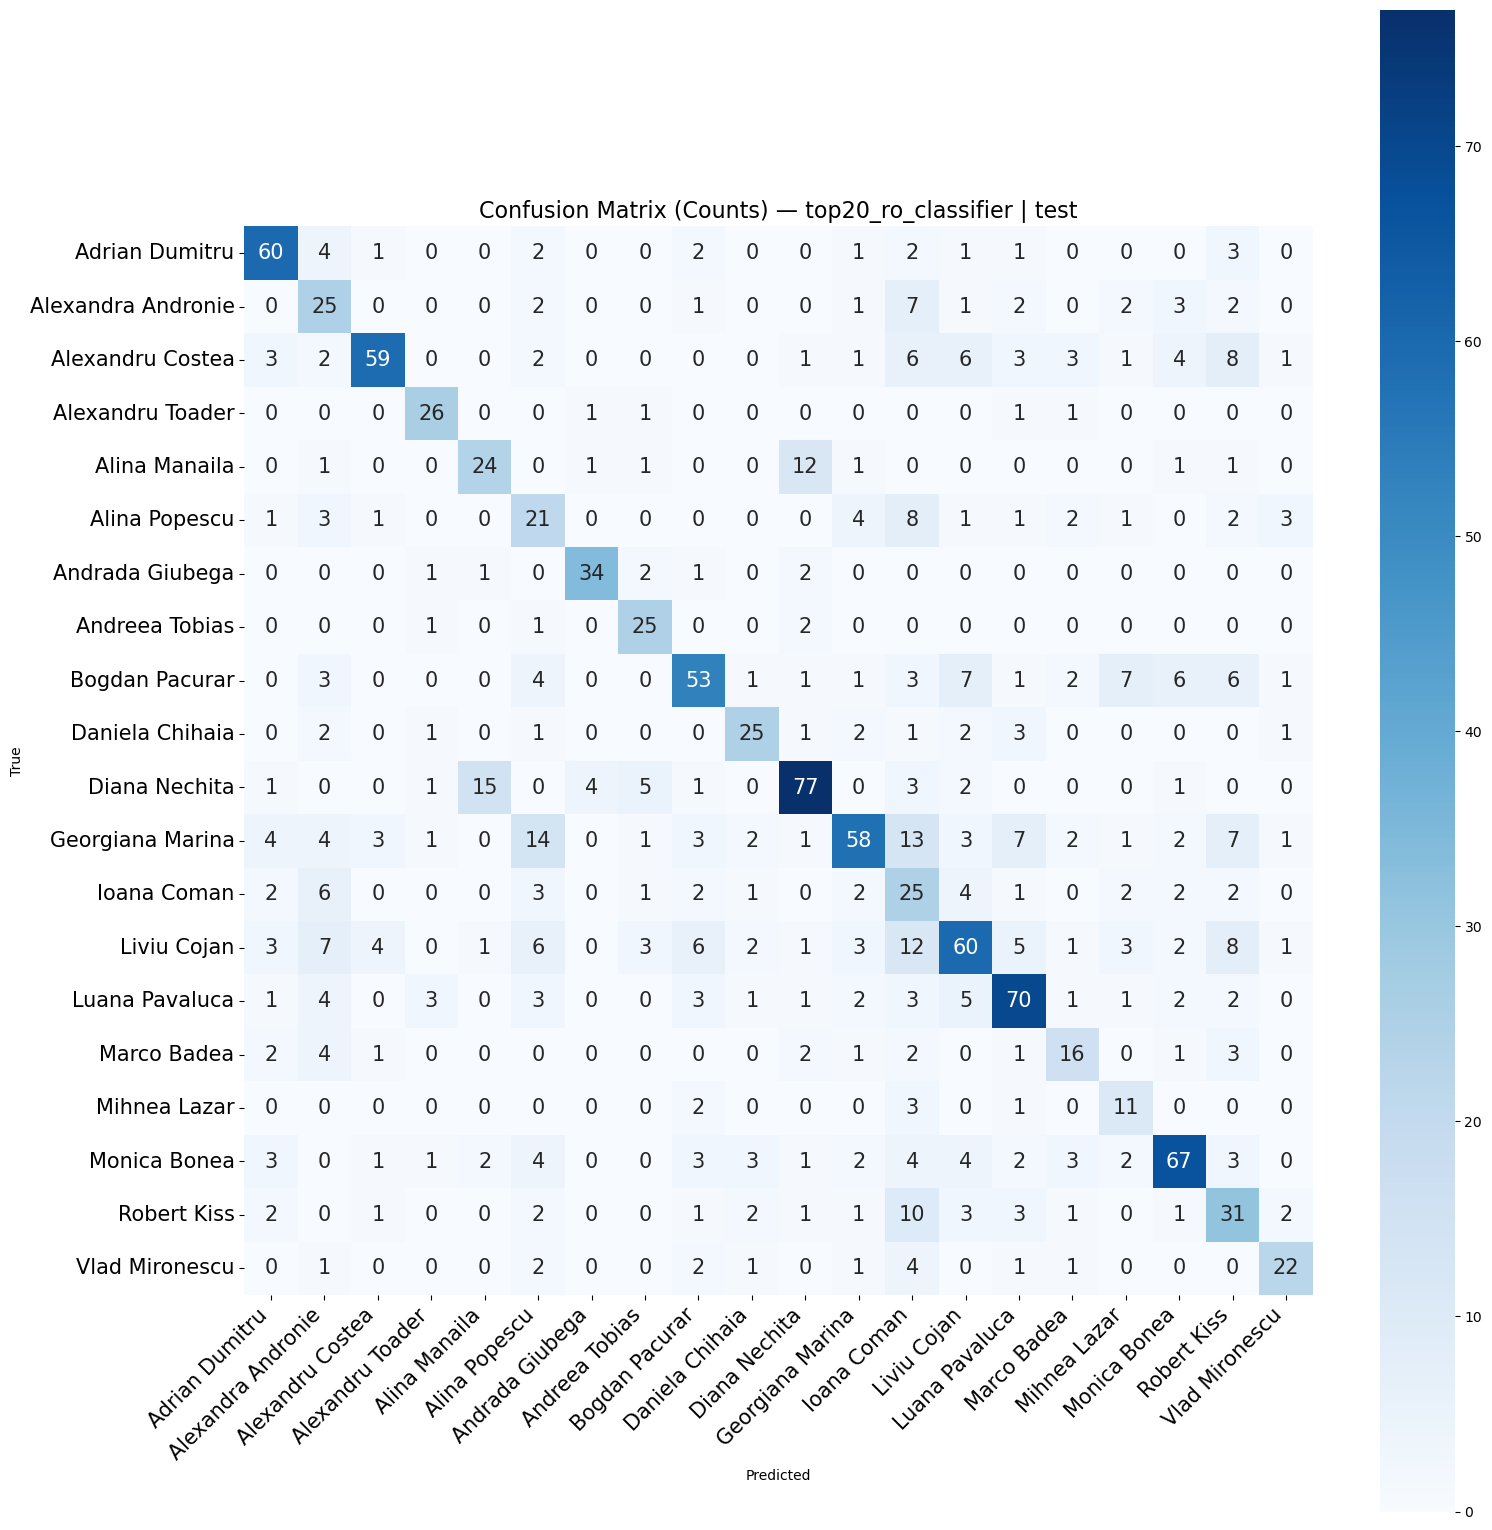

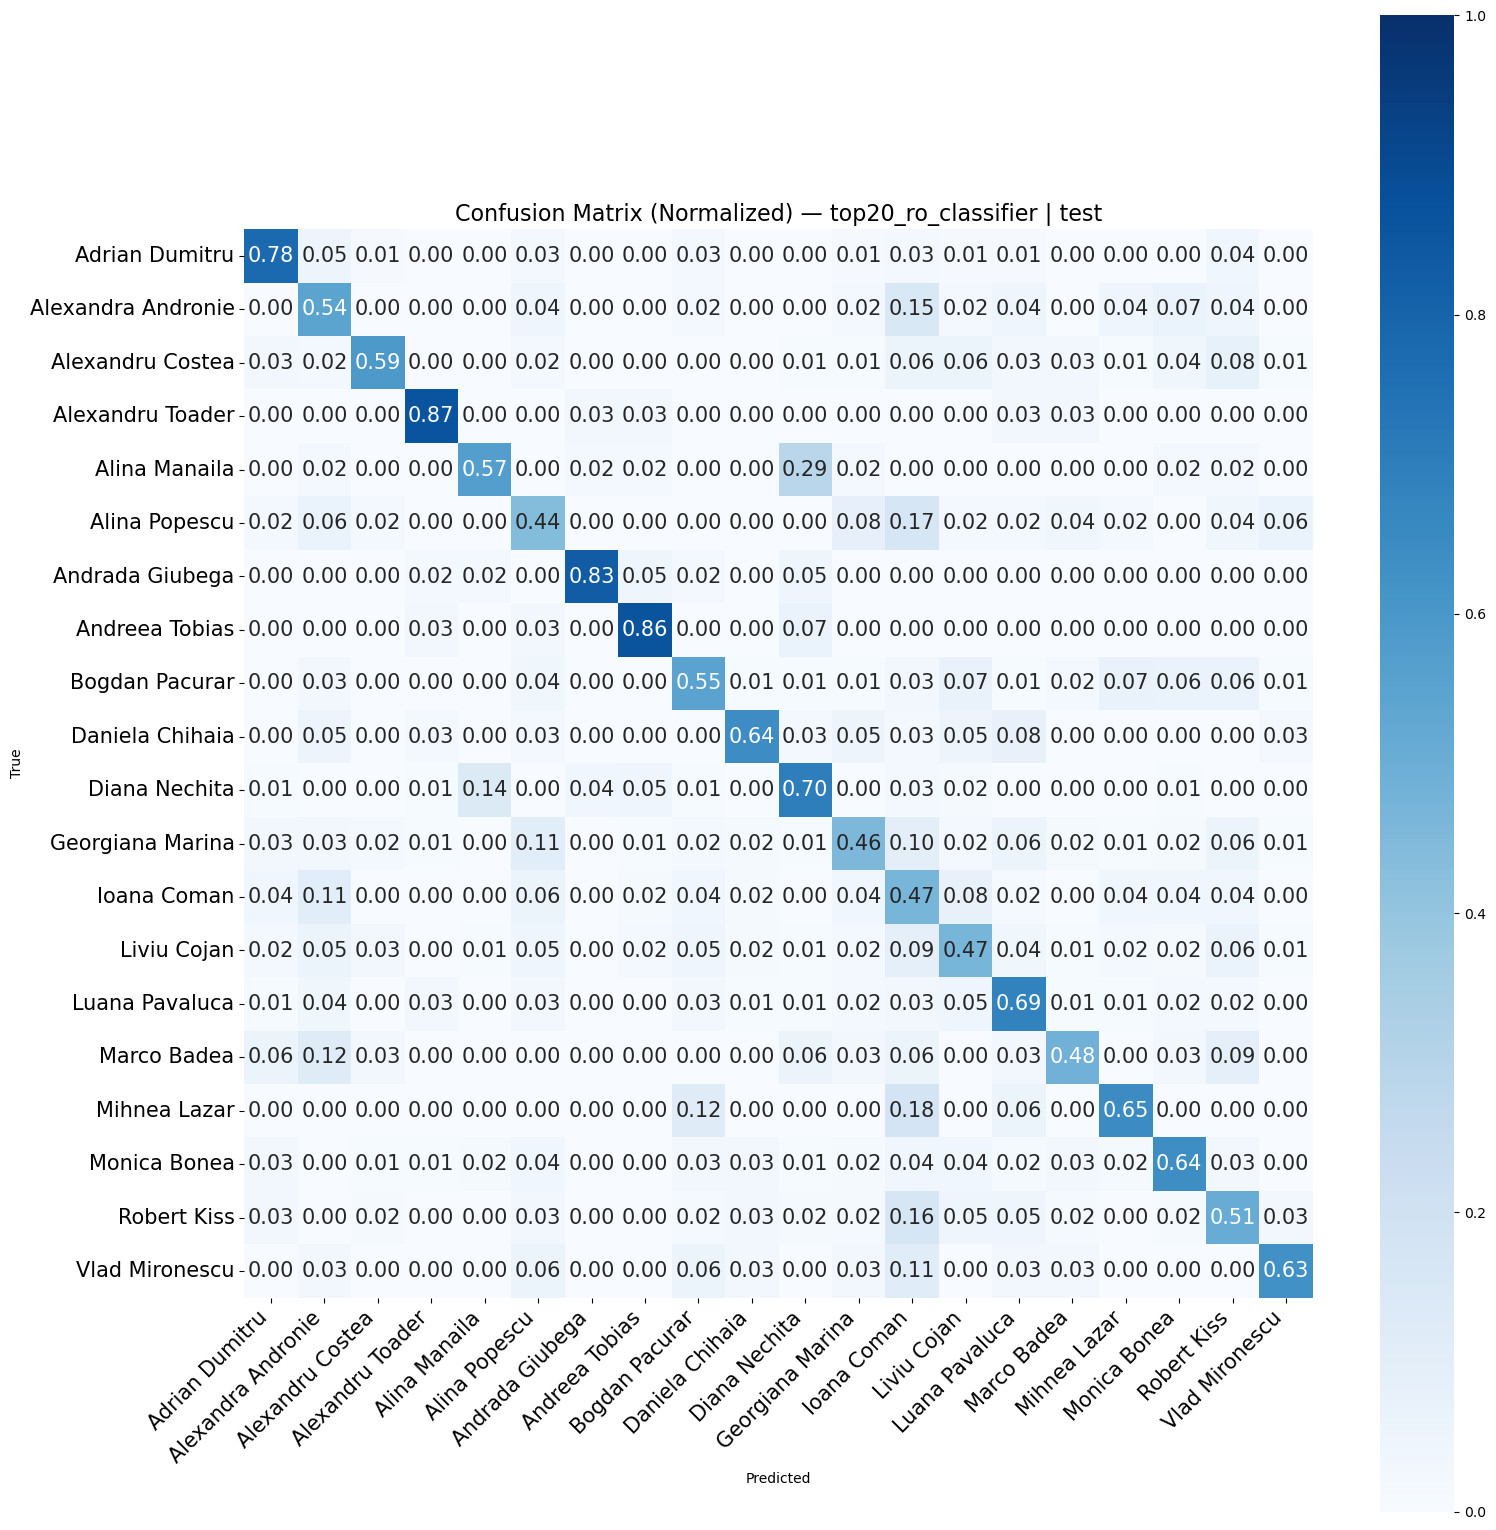

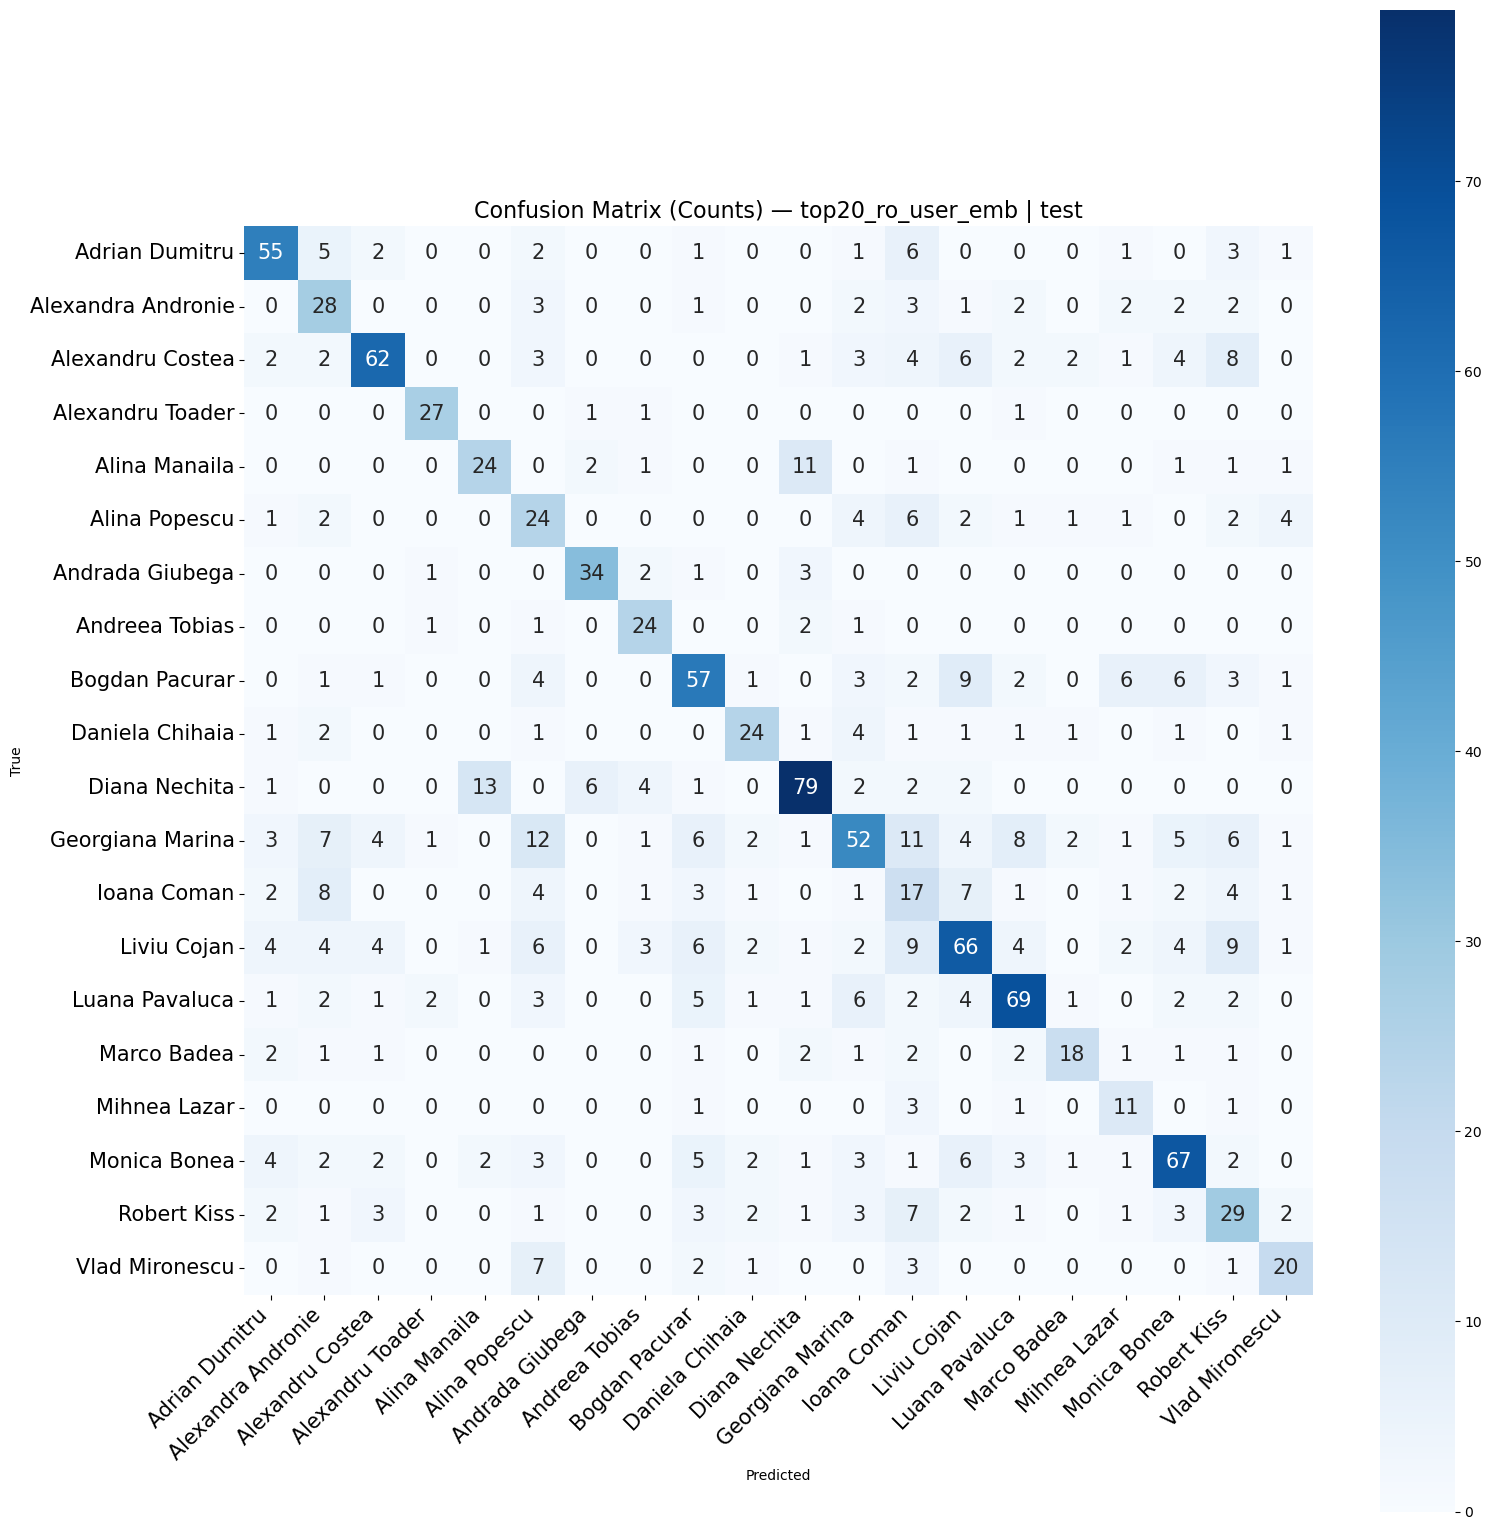

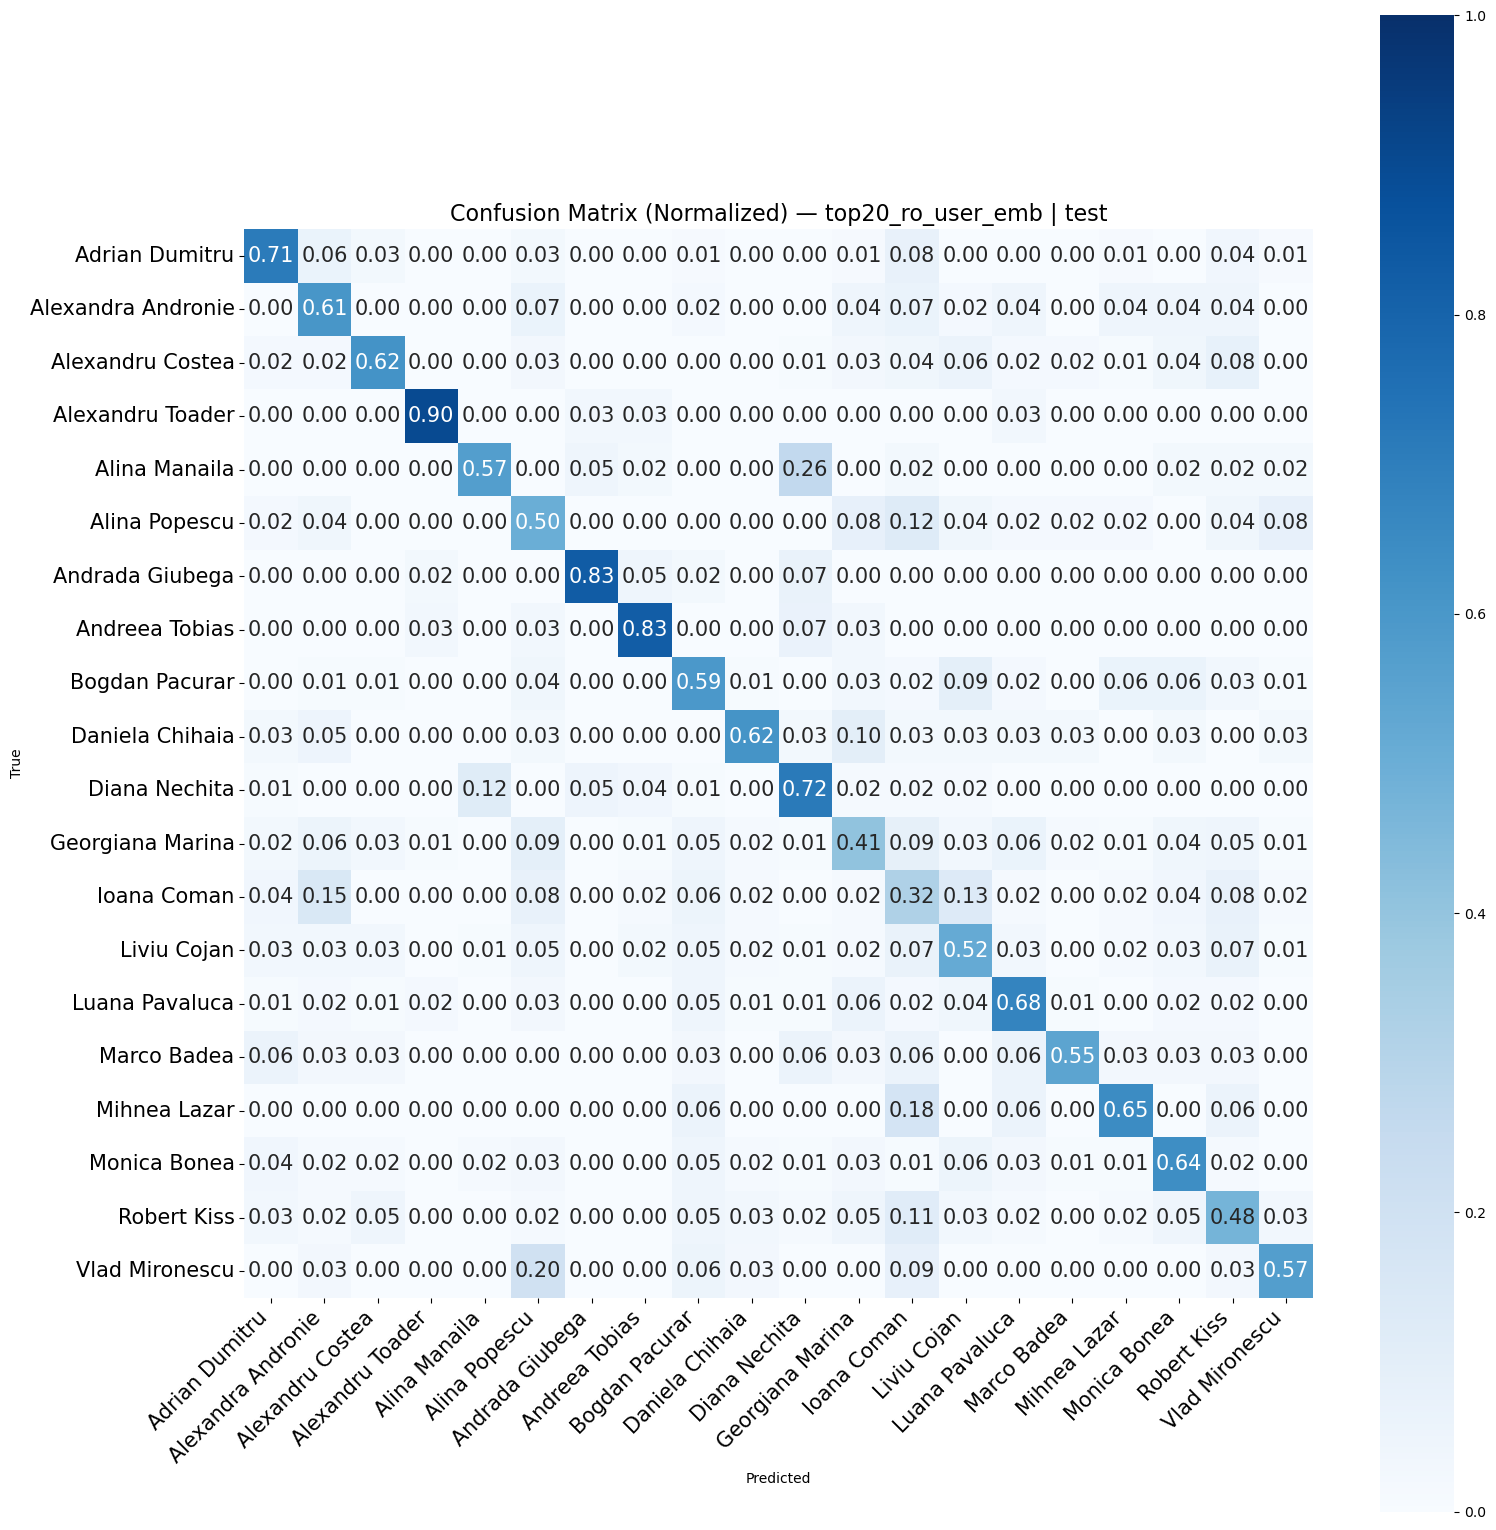


=== REZULTATE FINALE ===
Varianta A (clasificator): F1=0.5990 | Acc=0.5982
Varianta B (user emb):     F1=0.6009 | Acc=0.5967

=== Ranking Metrics (test) ===

=== Ranking Metrics — top20_ro_test ===
  P@1                 : 0.5989
  P@3                 : 0.7923
  P@5                 : 0.8597
  MRR                 : 0.7158
  Mean Rank           : 2.6444
  Coverage Error      : 2.6444
  LRAP                : 0.7158

=== Ranking Metrics (val) ===

=== Ranking Metrics — top20_ro_val ===
  P@1                 : 0.6015
  P@3                 : 0.7993
  P@5                 : 0.8761
  MRR                 : 0.7217
  Mean Rank           : 2.5813
  Coverage Error      : 2.5813
  LRAP                : 0.7217

Metrici salvate.


In [ ]:
# test
metrics = evaluate_model(
    model_path='outputs_contrastive_1/top20_ro/best_contrastive_top20_ro.pt',
    le=le,
    texts_train_w=texts_train_w,
    y_train_w=y_train_w,
    texts_val=texts_val,
    y_val=y_val,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name='top20_ro'
)
# 26 minute ca construieste embeddinguri


Incarc embeddings de pe disc...
  User embs:  20 autori
  Val embs:   (1340, 128)
  Test embs:  (1319, 128)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top20_ro/best_contrastive_top20_ro.pt

=== Varianta A: clasificator + voting ===

--- Varianta A: clasificator + voting ---
  0/1319
  100/1319
  200/1319
  300/1319
  400/1319
  500/1319
  600/1319
  700/1319
  800/1319
  900/1319
  1000/1319
  1100/1319
  1200/1319
  1300/1319
F1: 0.5990 | Acc: 0.5982
                    precision    recall  f1-score   support

    Adrian Dumitru       0.73      0.78      0.75        77
Alexandra Andronie       0.38      0.54      0.45        46
  Alexandru Costea       0.83      0.59      0.69       100
  Alexandru Toader       0.74      0.87      0.80        30
     Alina Manaila       0.56      0.57      0.56        42
     Alina Popescu       0.31      0.44      0.37        48
   Andrada Giubega       0.85      0.83      0.84        41
    Andreea Tobias       0.64      0.86      0.74        29
    Bogdan Pacurar       0.66      0.55      0.60        96
   Daniela Chihaia       0.66      0.64      0.65       

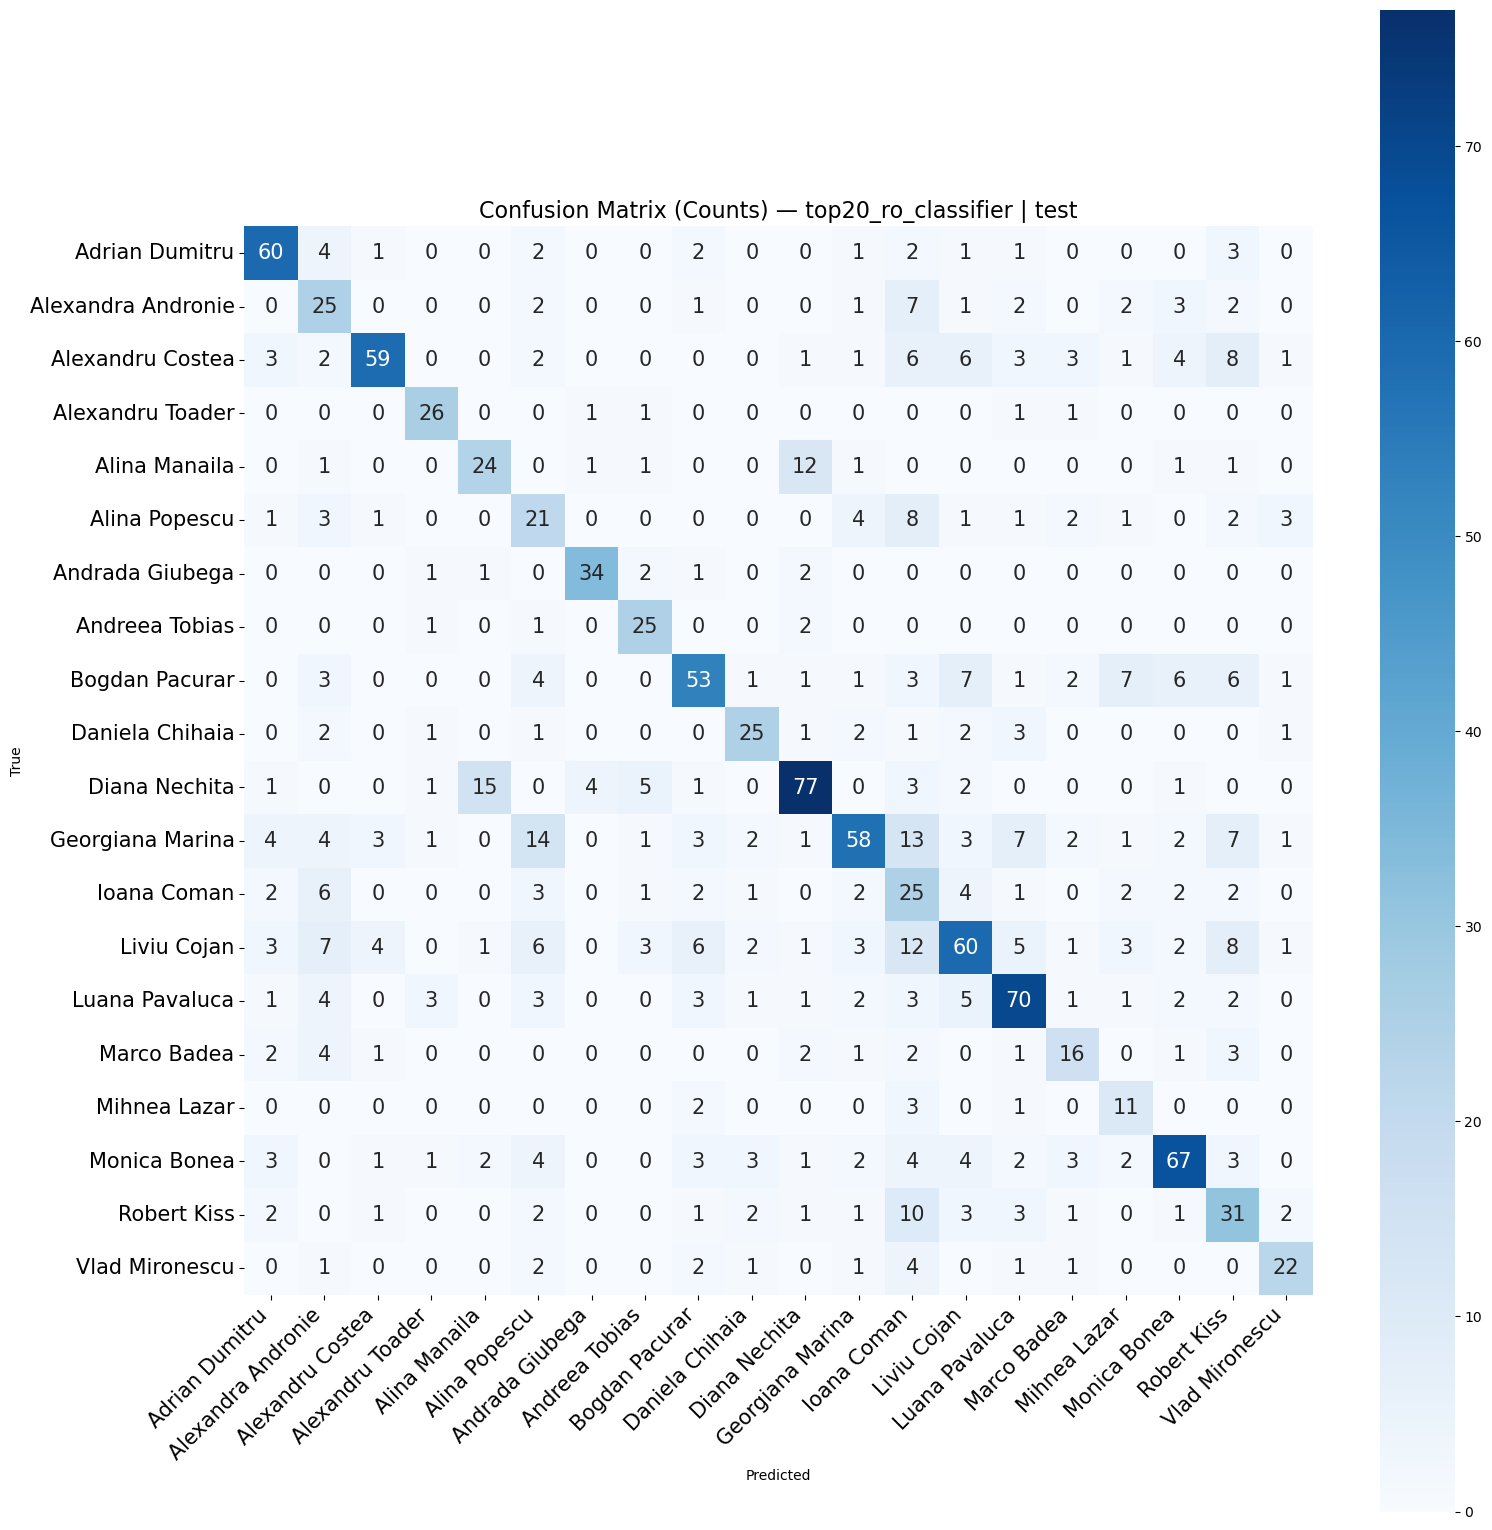

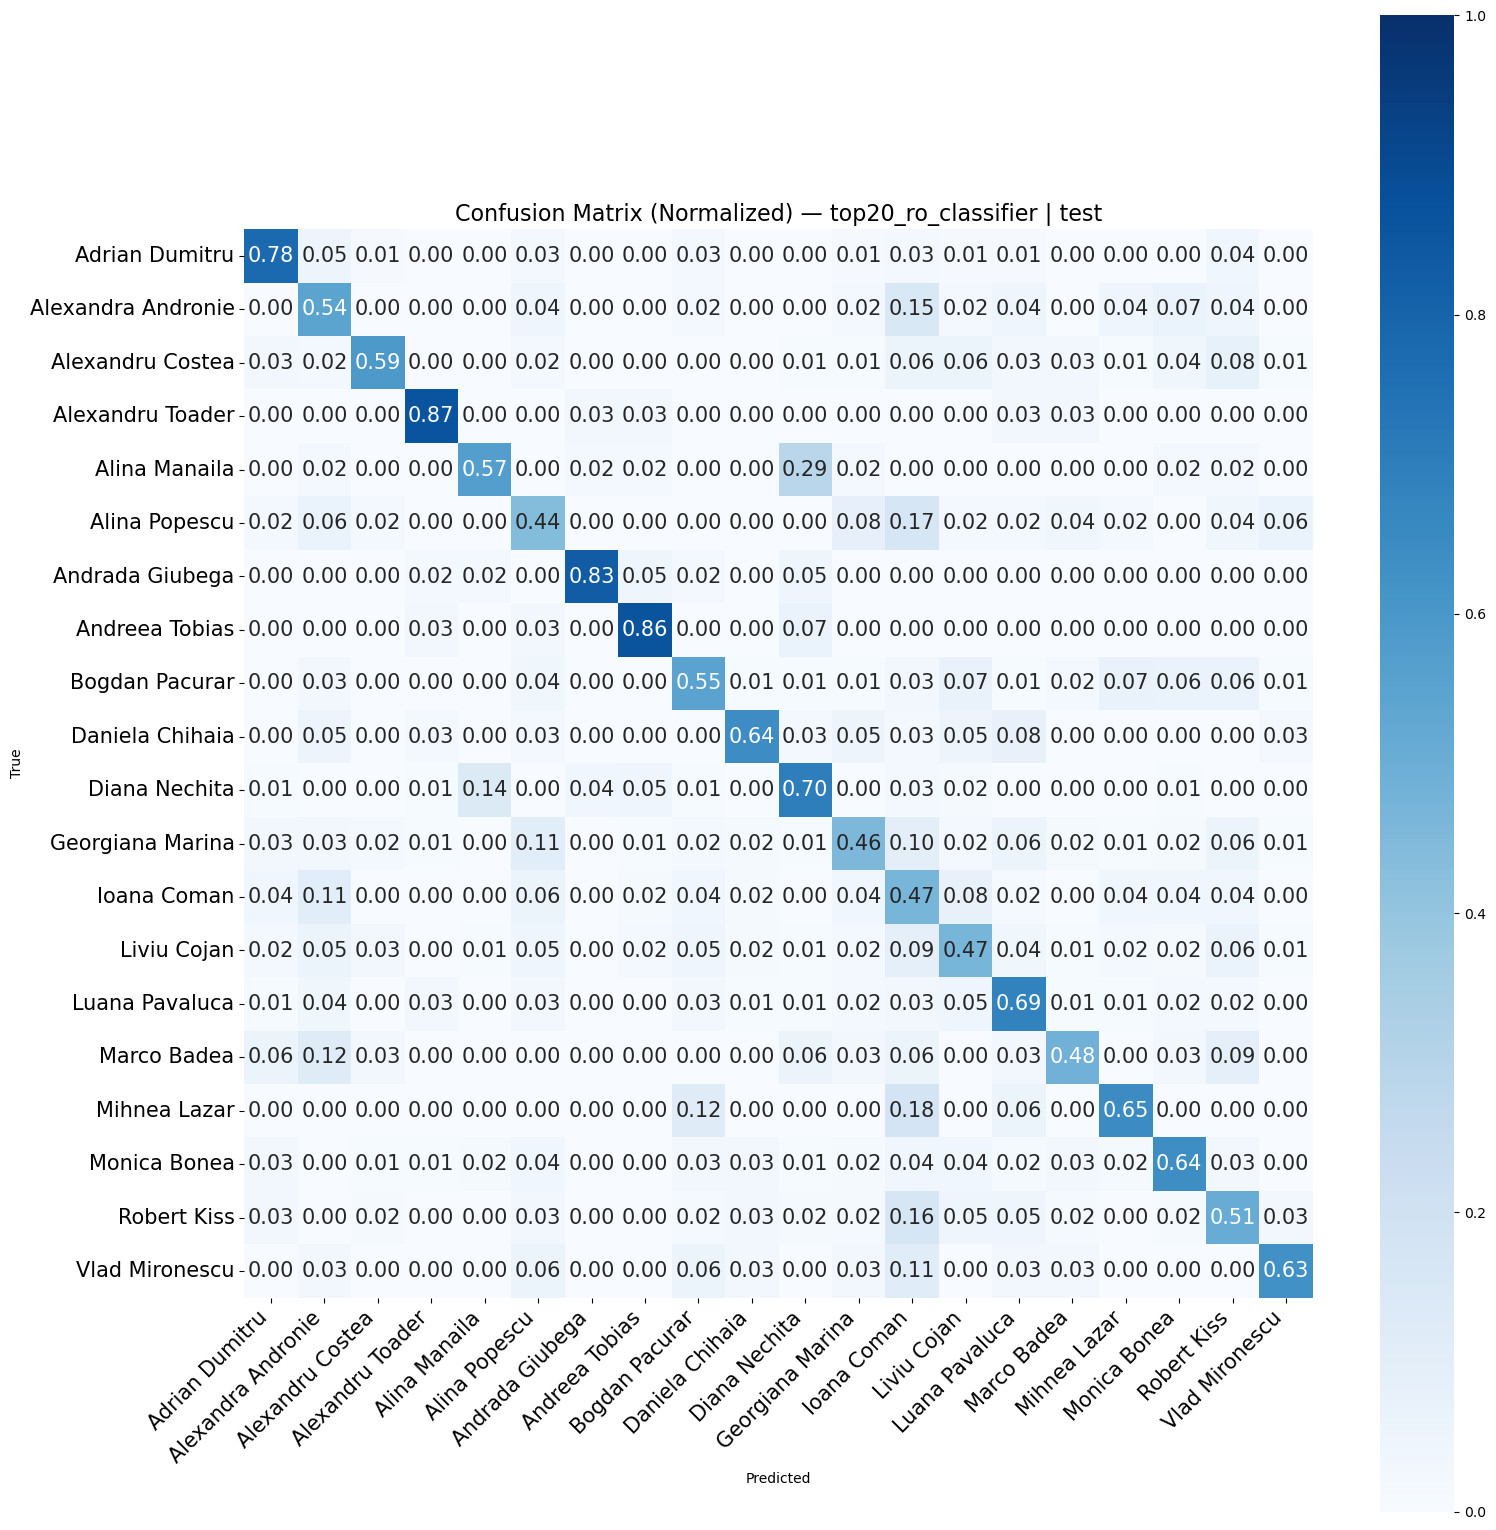

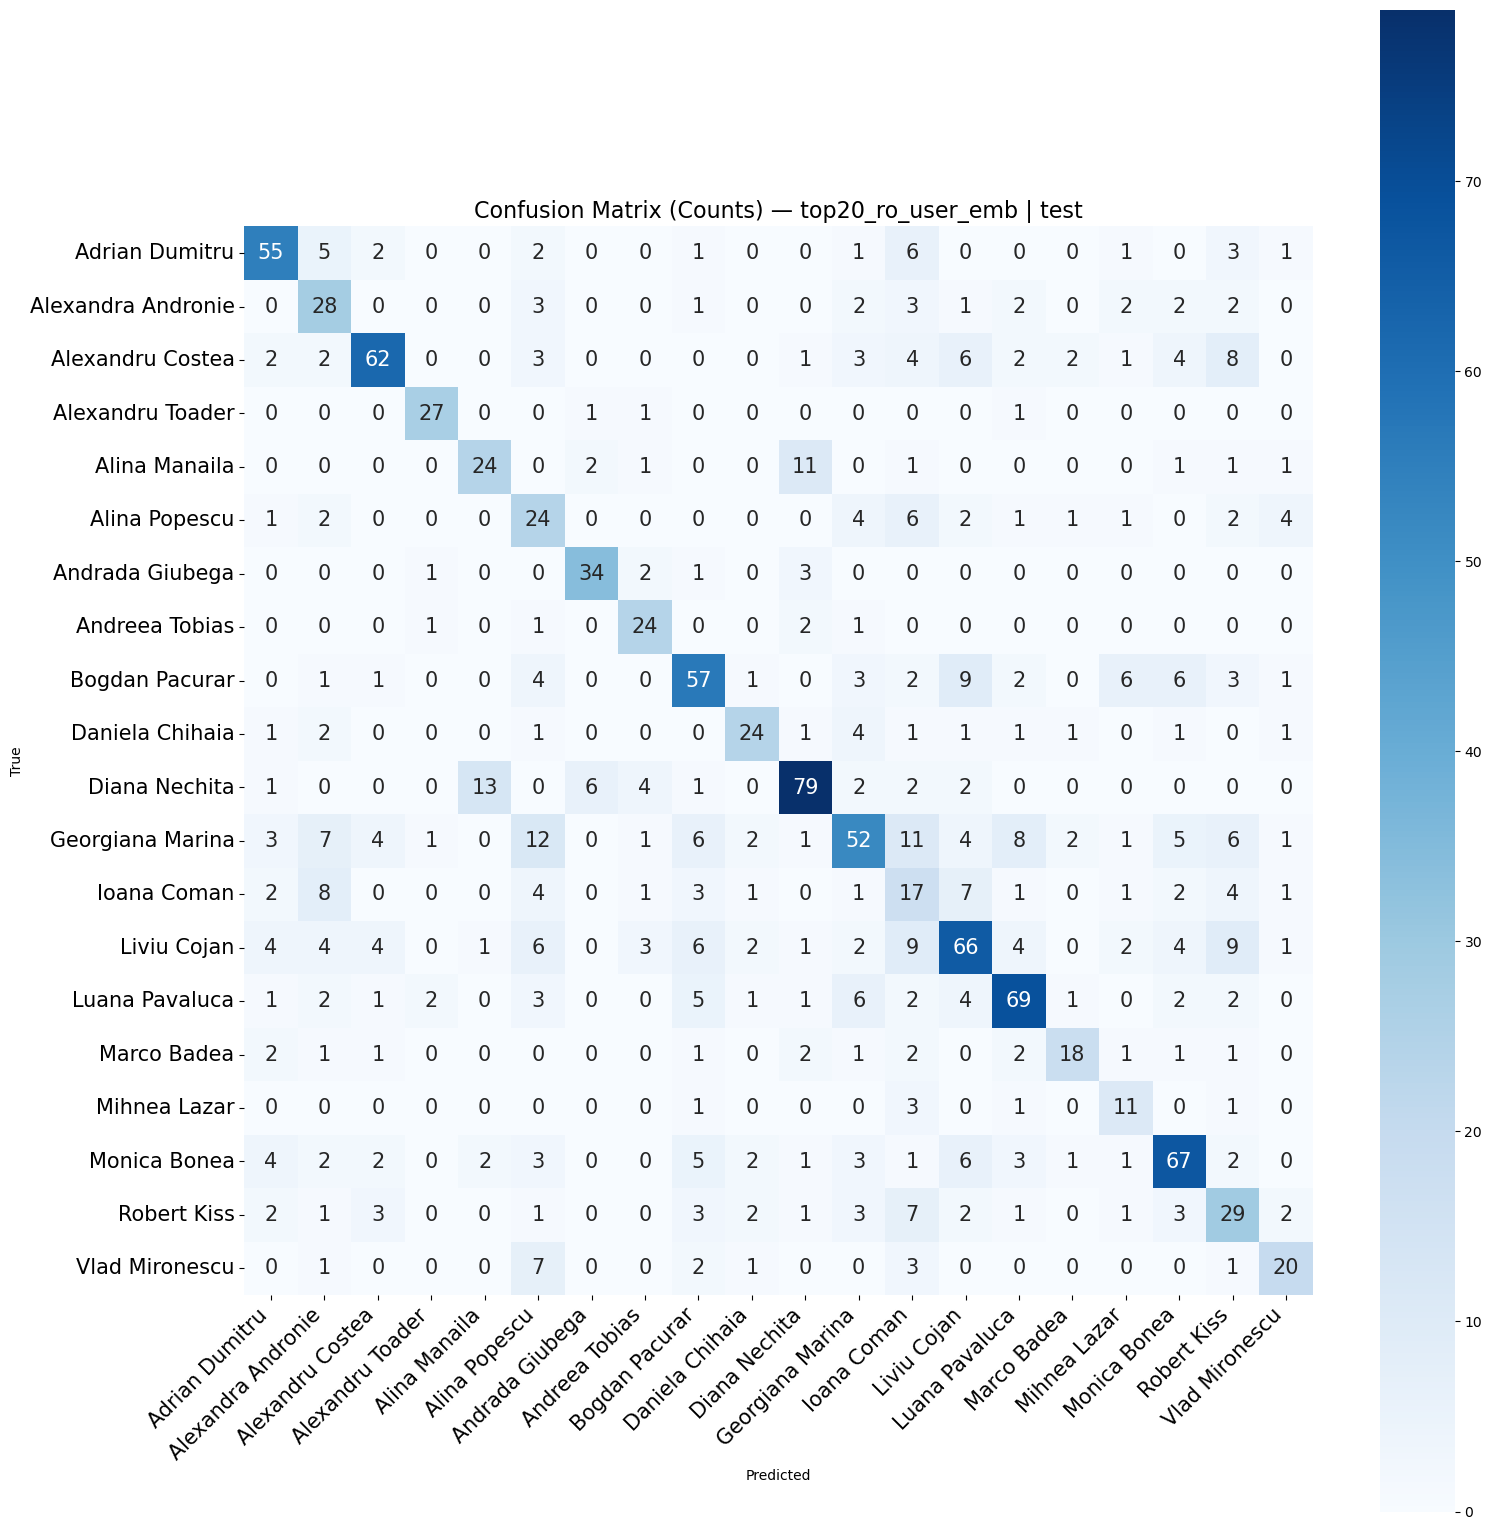

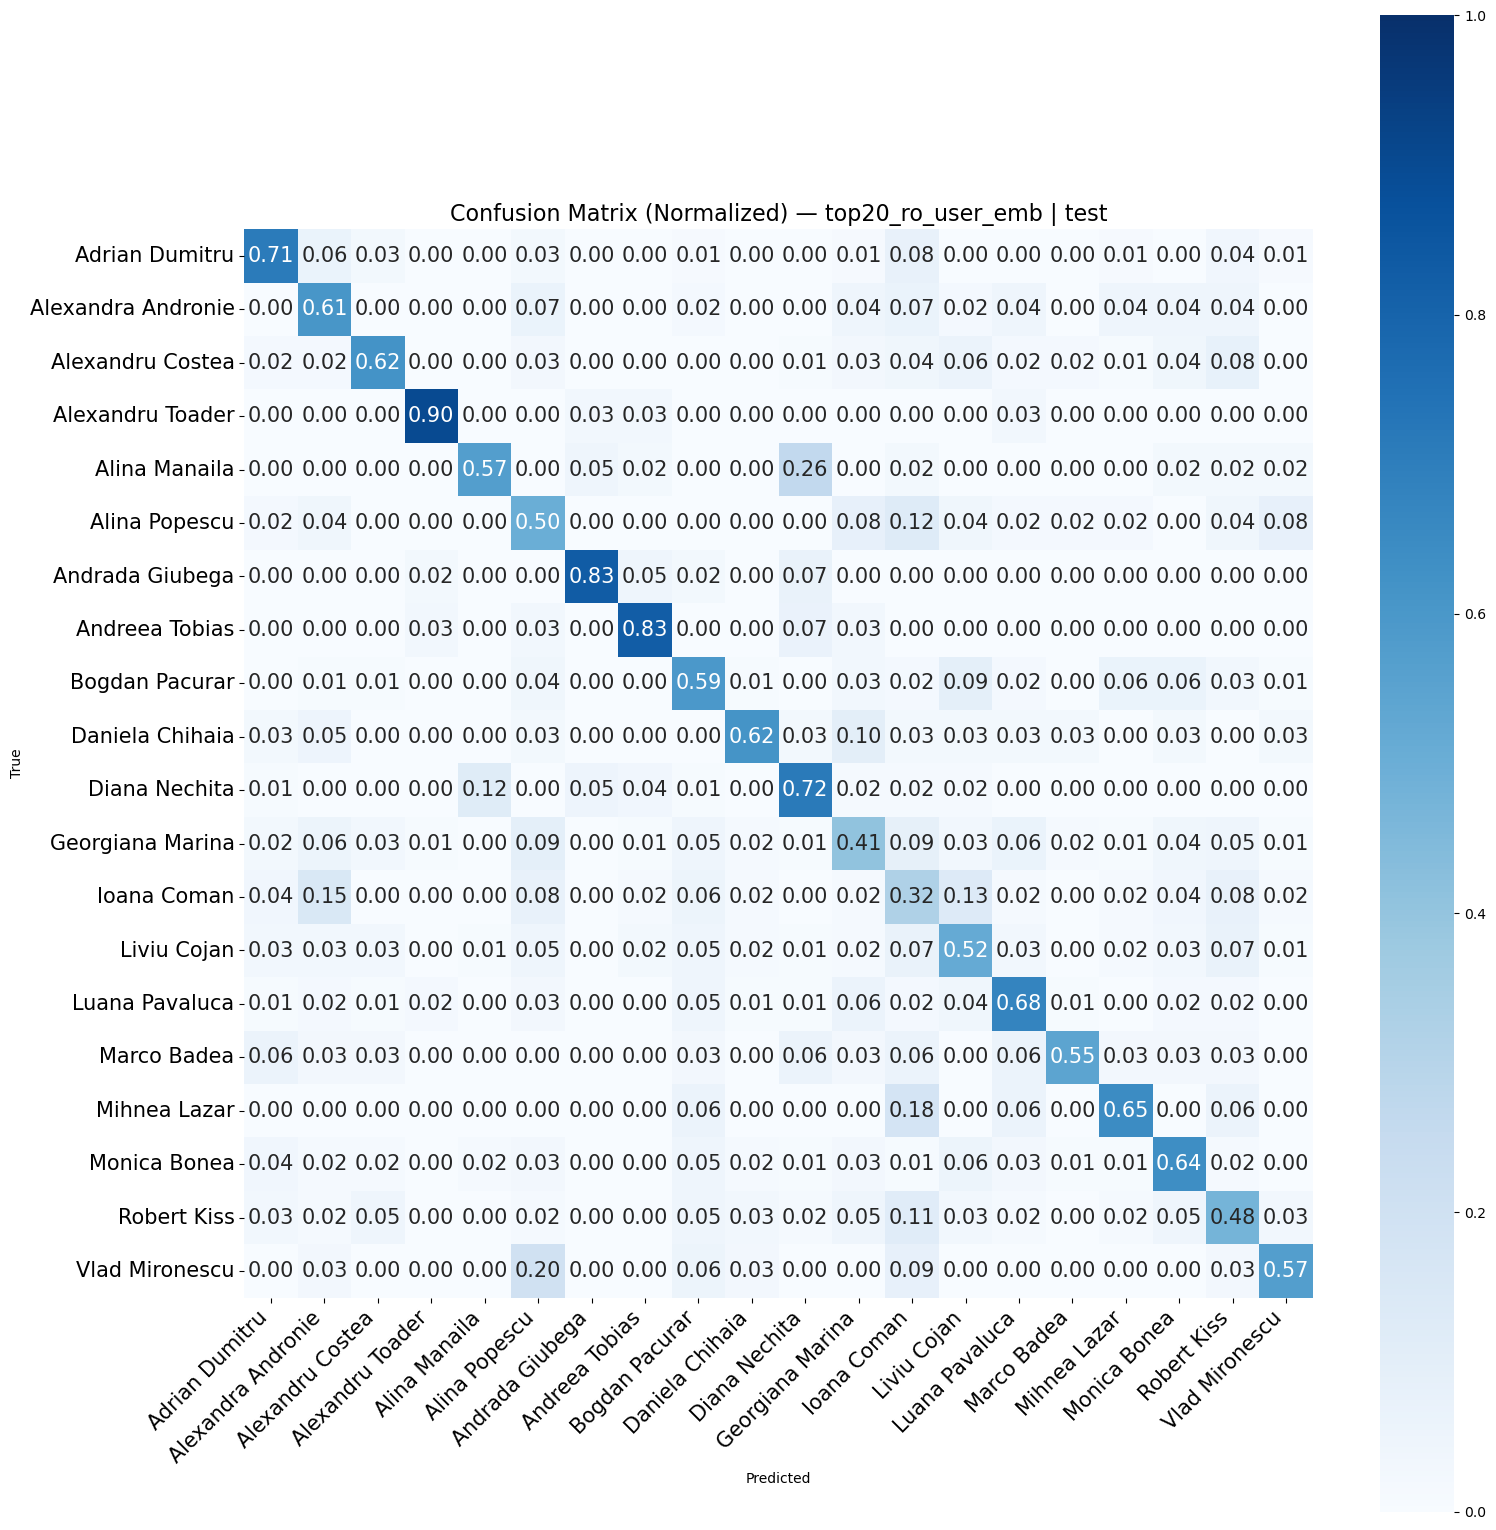


=== REZULTATE FINALE ===
Varianta A: F1=0.5990 | Acc=0.5982
Varianta B: F1=0.6009 | Acc=0.5967

=== Ranking Metrics (test) ===

=== Ranking Metrics — top20_ro_test ===
  P@1                 : 0.5989
  P@3                 : 0.7923
  P@5                 : 0.8597
  MRR                 : 0.7158
  Mean Rank           : 2.6444
  Coverage Error      : 2.6444
  LRAP                : 0.7158

=== Ranking Metrics (val) ===

=== Ranking Metrics — top20_ro_val ===
  P@1                 : 0.6015
  P@3                 : 0.7993
  P@5                 : 0.8761
  MRR                 : 0.7217
  Mean Rank           : 2.5813
  Coverage Error      : 2.5813
  LRAP                : 0.7217

  SUMAR FINAL — top20_ro
  Metrica                         Test        Val
  ---------------------------------------------
  F1 Classifier                 0.5990
  Acc Classifier                0.5982
  F1 User Emb                   0.6009
  Acc User Emb                  0.5967
  --------------------------------------------

In [ ]:
# oricand dupa — doar incarca si evalueaza
metrics = evaluate_from_embeddings(
    model_path='outputs_contrastive_1/top20_ro/best_contrastive_top20_ro.pt',
    le=le,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name='top20_ro'
)
# 1 minut

In [34]:
# extrag doc embeddings din train
extract_train_doc_embeddings(
    model_path='outputs_contrastive_1/top20_ro/best_contrastive_top20_ro.pt',
    train_df=pd.read_csv('final_stilo/top20_ro_train.csv'),
    label_encoder=le,
    save_path='outputs_contrastive_1/top20_ro/train_embeddings_top20_ro.npz',
    tokenizer=tokenizer,
    device=device
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top20_ro/best_contrastive_top20_ro.pt

=== Doc Embeddings (train) ===
  0/49696
  100/49696
  200/49696
  300/49696
  400/49696
  500/49696
  600/49696
  700/49696
  800/49696
  900/49696
  1000/49696
  1100/49696
  1200/49696
  1300/49696
  1400/49696
  1500/49696
  1600/49696
  1700/49696
  1800/49696
  1900/49696
  2000/49696
  2100/49696
  2200/49696
  2300/49696
  2400/49696
  2500/49696
  2600/49696
  2700/49696
  2800/49696
  2900/49696
  3000/49696
  3100/49696
  3200/49696
  3300/49696
  3400/49696
  3500/49696
  3600/49696
  3700/49696
  3800/49696
  3900/49696
  4000/49696
  4100/49696
  4200/49696
  4300/49696
  4400/49696
  4500/49696
  4600/49696
  4700/49696
  4800/49696
  4900/49696
  5000/49696
  5100/49696
  5200/49696
  5300/49696
  5400/49696
  5500/49696
  5600/49696
  5700/49696
  5800/49696
  5900/49696
  6000/49696
  6100/49696
  6200/49696
  6300/49696
  6400/49696
  6500/49696
  6600/49696
  6700/49696
  6800/49696
  6900/

### Romania top 40

In [27]:
# doar prepare_data + evaluate_model
(le,
 texts_train_w, y_train_w,
 texts_val,     y_val,
 texts_test,    y_test,
 val_loader,    test_loader) = prepare_data(
    'final_stilo/top40_ro_train.csv',
    'final_stilo/top40_ro_val.csv',
    'final_stilo/top40_ro_test.csv'
)


=== Pregatire date ===
Texte originale: 66991
Ferestre totale: 91414
  autor 0: 3367 ferestre
  autor 1: 2519 ferestre
  autor 2: 5131 ferestre
  autor 3: 1570 ferestre
  autor 4: 2466 ferestre
  autor 5: 2201 ferestre
  autor 6: 1344 ferestre
  autor 7: 1000 ferestre
  autor 8: 2075 ferestre
  autor 9: 993 ferestre
  autor 10: 1494 ferestre
  autor 11: 5211 ferestre
  autor 12: 1487 ferestre
  autor 13: 1064 ferestre
  autor 14: 1084 ferestre
  autor 15: 1305 ferestre
  autor 16: 1475 ferestre
  autor 17: 710 ferestre
  autor 18: 2074 ferestre
  autor 19: 5076 ferestre
  autor 20: 1108 ferestre
  autor 21: 881 ferestre
  autor 22: 6331 ferestre
  autor 23: 2930 ferestre
  autor 24: 1339 ferestre
  autor 25: 901 ferestre
  autor 26: 6011 ferestre
  autor 27: 5938 ferestre
  autor 28: 1057 ferestre
  autor 29: 2762 ferestre
  autor 30: 681 ferestre
  autor 31: 1363 ferestre
  autor 32: 5379 ferestre
  autor 33: 1209 ferestre
  autor 34: 1006 ferestre
  autor 35: 1804 ferestre
  autor 3

In [ ]:
# train
model, model_path, history = train_model(
    texts_train_w, y_train_w,
    val_loader, le,
    dataset_name="top40_ro"
)
#249  minute


=== Antrenare ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Autori: 40
Min ferestre per autor: 681
Perechi per autor: 340
Total perechi: 13600
Batch size: 40
Batches per epoca: 340

Epoch 1/15
Autori: 40
Min ferestre per autor: 681
Perechi per autor: 340
Total perechi: 13600
Batch size: 40
Batches per epoca: 340


/tmp/ipykernel_74188/893405514.py:45: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
/tmp/ipykernel_74188/3432305241.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


...

Train - loss: 1.7753 CE: 1.1490 InfoNCE: 2.0876 F1: 0.6996
Val   - loss: 1.7045 F1: 0.5239 Acc: 0.5050
  Salvat (F1=0.5239)

Epoch 15/15
Autori: 40
Min ferestre per autor: 681
Perechi per autor: 340
Total perechi: 13600
Batch size: 40
Batches per epoca: 340


/tmp/ipykernel_74188/3432305241.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


  Batch 0/340 loss: 1.7694 CE: 1.1526 Loss infoNCE: 2.0560
  Batch 100/340 loss: 1.8629 CE: 1.2274 Loss infoNCE: 2.1184
  Batch 200/340 loss: 1.8201 CE: 1.1482 Loss infoNCE: 2.2398
  Batch 300/340 loss: 1.6810 CE: 1.0637 Loss infoNCE: 2.0579


/tmp/ipykernel_74188/2837057539.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_74188/2837057539.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Train - loss: 1.7623 CE: 1.1315 InfoNCE: 2.1028 F1: 0.6905
Val   - loss: 1.7076 F1: 0.5293 Acc: 0.5073
  Salvat (F1=0.5293)

Best Val F1: 0.5293

**BEST VAL F1**:  0.5292632134041622


In [29]:
# test
metrics = evaluate_model(
    model_path='outputs_contrastive_1/top40_ro/best_contrastive_top40_ro.pt',
    le=le,
    texts_train_w=texts_train_w,
    y_train_w=y_train_w,
    texts_val=texts_val,
    y_val=y_val,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name='top40_ro'
)
# minute ca construieste embeddinguri

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top40_ro/best_contrastive_top40_ro.pt

=== User Embeddings (train) ===
  Adrian Dumitru: 3367 texte
  Alexandra Andronie: 2519 texte
  Alexandru Costea: 5131 texte
  Alexandru Toader: 1570 texte
  Alina Manaila: 2466 texte
  Alina Popescu: 2201 texte
  Ana Petrescu: 1344 texte
  Anca Dumitrescu: 1000 texte
  Andrada Giubega: 2075 texte
  Andreea Neblea: 993 texte
  Andreea Tobias: 1494 texte
  Bogdan Pacurar: 5211 texte
  Carmen Zanfir: 1487 texte
  Catalin Costache: 1064 texte
  Cosmin Pirv: 1084 texte
  Cristian Anton: 1305 texte
  Cristian Matei: 1475 texte
  Dan Duca: 710 texte
  Daniela Chihaia: 2074 texte
  Diana Nechita: 5076 texte
  Dorin Oancea: 1108 texte
  Georgel Costita: 881 texte
  Georgiana Marina: 6331 texte
  Ioana Coman: 2930 texte
  Laura Buciu: 1339 texte
  Leila Bolat: 901 texte
  Liviu Cojan: 6011 texte
  Luana Pavaluca: 5938 texte
  Luminita Turcu: 1057 texte
  Marco Badea: 2762 texte
  Mihai Draghici: 681 texte
  Mihnea Laza

In [ ]:
# oricand dupa — doar incarca si evalueaza
metrics = evaluate_from_embeddings(
    model_path='outputs_contrastive_1/top40_ro/best_contrastive_top40_ro.pt',
    le=le,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name='top40_ro'
)
# 1 minut

In [ ]:
# extrag doc embeddings din train
extract_train_doc_embeddings(
    model_path='outputs_contrastive_1/top40_ro/best_contrastive_top40_ro.pt',
    train_df=pd.read_csv('final_stilo/top40_ro_train.csv'),
    label_encoder=le,
    save_path='outputs_contrastive_1/top40_ro/train_embeddings_top40_ro.npz',
    tokenizer=tokenizer,
    device=device
)

### Moldova top 20

In [30]:
# doar prepare_data + evaluate_model
(le,
 texts_train_w, y_train_w,
 texts_val,     y_val,
 texts_test,    y_test,
 val_loader,    test_loader) = prepare_data(
    'final_stilo/top20_mo_train.csv',
    'final_stilo/top20_mo_val.csv',
    'final_stilo/top20_mo_test.csv'
)


=== Pregatire date ===
Texte originale: 39332
Ferestre totale: 51976
  autor 0: 1895 ferestre
  autor 1: 1131 ferestre
  autor 2: 3169 ferestre
  autor 3: 1684 ferestre
  autor 4: 2886 ferestre
  autor 5: 2841 ferestre
  autor 6: 3042 ferestre
  autor 7: 3160 ferestre
  autor 8: 1523 ferestre
  autor 9: 1246 ferestre
  autor 10: 2615 ferestre
  autor 11: 2151 ferestre
  autor 12: 3502 ferestre
  autor 13: 4018 ferestre
  autor 14: 1410 ferestre
  autor 15: 6795 ferestre
  autor 16: 3829 ferestre
  autor 17: 2341 ferestre
  autor 18: 1161 ferestre
  autor 19: 1577 ferestre
Numar autori: 20


In [ ]:
# train
model, model_path, history = train_model(
    texts_train_w, y_train_w,
    val_loader, le,
    dataset_name="top20_mo"
)
#228 minute


=== Antrenare ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Autori: 20
Min ferestre per autor: 1131
Perechi per autor: 565
Total perechi: 11300
Batch size: 20
Batches per epoca: 565

Epoch 1/15
Autori: 20
Min ferestre per autor: 1131
Perechi per autor: 565
Total perechi: 11300
Batch size: 20
Batches per epoca: 565


/tmp/ipykernel_74188/893405514.py:45: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
/tmp/ipykernel_74188/3432305241.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_74188/3432305241.py:36: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


...

Train - loss: 0.7620 CE: 0.5011 InfoNCE: 0.8698 F1: 0.8614
Val   - loss: 1.0940 F1: 0.6667 Acc: 0.6544
  Salvat (F1=0.6667)

Epoch 15/15
Autori: 20
Min ferestre per autor: 1131
Perechi per autor: 565
Total perechi: 11300
Batch size: 20
Batches per epoca: 565


/tmp/ipykernel_74188/3432305241.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


  Batch 0/565 loss: 0.6533 CE: 0.4568 Loss infoNCE: 0.6548
  Batch 100/565 loss: 1.1833 CE: 0.7802 Loss infoNCE: 1.3436
  Batch 200/565 loss: 0.6229 CE: 0.4065 Loss infoNCE: 0.7211
  Batch 300/565 loss: 0.6067 CE: 0.4201 Loss infoNCE: 0.6222
  Batch 400/565 loss: 0.4370 CE: 0.2337 Loss infoNCE: 0.6776
  Batch 500/565 loss: 0.5396 CE: 0.3781 Loss infoNCE: 0.5383


/tmp/ipykernel_74188/2837057539.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_74188/2837057539.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Train - loss: 0.7384 CE: 0.4830 InfoNCE: 0.8514 F1: 0.8547
Val   - loss: 1.0984 F1: 0.6651 Acc: 0.6520

Best Val F1: 0.6667

**BEST VAL F1**:  0.6667488104333892


In [32]:
# test
metrics = evaluate_model(
    model_path='outputs_contrastive_1/top20_mo/best_contrastive_top20_mo.pt',
    le=le,
    texts_train_w=texts_train_w,
    y_train_w=y_train_w,
    texts_val=texts_val,
    y_val=y_val,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name='top20_mo'
)
# minute ca construieste embeddinguri

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top20_mo/best_contrastive_top20_mo.pt

=== User Embeddings (train) ===
  Aliona Ciurca: 1895 texte
  Ana-Maria Dolghii: 1131 texte
  Cristian Sava: 3169 texte
  Cristina Dulea: 1684 texte
  Cristina Mirca: 2886 texte
  Cristina Popescu: 2841 texte
  Diana Gatcan: 3042 texte
  Diana Severin: 3160 texte
  Ecaterina Arvintii: 1523 texte
  Malvina Cojocari: 1246 texte
  Marina Ciobanu: 2615 texte
  Maxim Stratan: 2151 texte
  Mihaela Conovali: 3502 texte
  Milena Onisim: 4018 texte
  Nicoleta Braghis: 1410 texte
  Stela Untila: 6795 texte
  Svetlana Cartin: 3829 texte
  Svetlana Cojocaru: 2341 texte
  Valentina Buza: 1161 texte
  Viorica Rusu: 1577 texte
User embeddings salvate: outputs_contrastive_1/top20_mo/user_embeddings_top20_mo.pt

=== Doc Embeddings (val) ===
  0/4916
  100/4916
  200/4916
  300/4916
  400/4916
  500/4916
  600/4916
  700/4916
  800/4916
  900/4916
  1000/4916
  1100/4916
  1200/4916
  1300/4916
  1400/4916
  1500/4916
  1600/49

In [ ]:
# oricand dupa — doar incarca si evalueaza
metrics = evaluate_from_embeddings(
    model_path='outputs_contrastive_1/top20_mo/best_contrastive_top20_mo.pt',
    le=le,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name='top20_mo'
)
# 5 minut


Incarc embeddings de pe disc...
  User embs:  20 autori
  Val embs:   (4916, 128)
  Test embs:  (4917, 128)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top20_mo/best_contrastive_top20_mo.pt

=== Varianta A: clasificator + voting ===

--- Varianta A: clasificator + voting ---
  0/4917
  100/4917
  200/4917
  300/4917
  400/4917
  500/4917
  600/4917
  700/4917
  800/4917
  900/4917
  1000/4917
  1100/4917
  1200/4917
  1300/4917
  1400/4917
  1500/4917
  1600/4917
  1700/4917
  1800/4917
  1900/4917
  2000/4917
  2100/4917
  2200/4917
  2300/4917
  2400/4917
  2500/4917
  2600/4917
  2700/4917
  2800/4917
  2900/4917
  3000/4917
  3100/4917
  3200/4917
  3300/4917
  3400/4917
  3500/4917
  3600/4917
  3700/4917
  3800/4917
  3900/4917
  4000/4917
  4100/4917
  4200/4917
  4300/4917
  4400/4917
  4500/4917
  4600/4917
  4700/4917
  4800/4917
  4900/4917
F1: 0.6447 | Acc: 0.6372
                    precision    recall  f1-score   support

     Aliona Ciurca       0.78      0.72      0.75       150
 Ana-Maria Dolghii       0.44      0.58      0.50       121
     Cristian Sava       0.45      0.37     

In [ ]:
# extrag doc embeddings din train
extract_train_doc_embeddings(
    model_path='outputs_contrastive_1/top20_mo/best_contrastive_top20_mo.pt',
    train_df=pd.read_csv('final_stilo/top20_mo_train.csv'),
    label_encoder=le,
    save_path='outputs_contrastive_1/top20_mo/train_embeddings_top20_mo.npz',
    tokenizer=tokenizer,
    device=device
)
# 23 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top20_mo/best_contrastive_top20_mo.pt

=== Doc Embeddings (train) ===
  0/39332
  100/39332
  200/39332
  300/39332
  400/39332
  500/39332
  600/39332
  700/39332
  800/39332
  900/39332
  1000/39332
  1100/39332
  1200/39332
  1300/39332
  1400/39332
  1500/39332
  1600/39332
  1700/39332
  1800/39332
  1900/39332
  2000/39332
  2100/39332
  2200/39332
  2300/39332
  2400/39332
  2500/39332
  2600/39332
  2700/39332
  2800/39332
  2900/39332
  3000/39332
  3100/39332
  3200/39332
  3300/39332
  3400/39332
  3500/39332
  3600/39332
  3700/39332
  3800/39332
  3900/39332
  4000/39332
  4100/39332
  4200/39332
  4300/39332
  4400/39332
  4500/39332
  4600/39332
  4700/39332
  4800/39332
  4900/39332
  5000/39332
  5100/39332
  5200/39332
  5300/39332
  5400/39332
  5500/39332
  5600/39332
  5700/39332
  5800/39332
  5900/39332
  6000/39332
  6100/39332
  6200/39332
  6300/39332
  6400/39332
  6500/39332
  6600/39332
  6700/39332
  6800/39332
  6900/

### Moldova top 40

In [28]:
# doar prepare_data + evaluate_model
(le,
 texts_train_w, y_train_w,
 texts_val,     y_val,
 texts_test,    y_test,
 val_loader,    test_loader) = prepare_data(
    'final_stilo/top40_mo_train.csv',
    'final_stilo/top40_mo_val.csv',
    'final_stilo/top40_mo_test.csv'
)


=== Pregatire date ===
Texte originale: 47215
Ferestre totale: 63717
  autor 0: 203 ferestre
  autor 1: 1892 ferestre
  autor 2: 1126 ferestre
  autor 3: 280 ferestre
  autor 4: 930 ferestre
  autor 5: 452 ferestre
  autor 6: 831 ferestre
  autor 7: 3179 ferestre
  autor 8: 1669 ferestre
  autor 9: 2883 ferestre
  autor 10: 2849 ferestre
  autor 11: 3063 ferestre
  autor 12: 3187 ferestre
  autor 13: 660 ferestre
  autor 14: 1516 ferestre
  autor 15: 143 ferestre
  autor 16: 551 ferestre
  autor 17: 759 ferestre
  autor 18: 479 ferestre
  autor 19: 1225 ferestre
  autor 20: 951 ferestre
  autor 21: 1184 ferestre
  autor 22: 2573 ferestre
  autor 23: 2153 ferestre
  autor 24: 3492 ferestre
  autor 25: 4054 ferestre
  autor 26: 1376 ferestre
  autor 27: 6862 ferestre
  autor 28: 3829 ferestre
  autor 29: 2349 ferestre
  autor 30: 1254 ferestre
  autor 31: 145 ferestre
  autor 32: 92 ferestre
  autor 33: 153 ferestre
  autor 34: 1164 ferestre
  autor 35: 364 ferestre
  autor 36: 1410 fer

In [29]:
# train
model, model_path, history = train_model(
    texts_train_w, y_train_w,
    val_loader, le,
    dataset_name="top40_mo"
)
# minute


=== Antrenare ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Autori: 40
Min ferestre per autor: 92
Perechi per autor: 46
Total perechi: 1840
Batch size: 40
Batches per epoca: 46

Epoch 1/15
Autori: 40
Min ferestre per autor: 92
Perechi per autor: 46
Total perechi: 1840
Batch size: 40
Batches per epoca: 46


/tmp/ipykernel_107898/893405514.py:45: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
/tmp/ipykernel_107898/3432305241.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/tmp/ipykernel_107898/3432305241.py:36: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  

...

Train - loss: 3.0109 CE: 2.1263 InfoNCE: 2.9489 F1: 0.3839
Val   - loss: 2.3672 F1: 0.2582 Acc: 0.2442
  Salvat (F1=0.2582)

Epoch 15/15
Autori: 40
Min ferestre per autor: 92
Perechi per autor: 46
Total perechi: 1840
Batch size: 40
Batches per epoca: 46


/tmp/ipykernel_107898/3432305241.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


  Batch 0/46 loss: 3.3377 CE: 2.4021 Loss infoNCE: 3.1186


/tmp/ipykernel_107898/2837057539.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_107898/2837057539.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Train - loss: 3.0280 CE: 2.1556 InfoNCE: 2.9081 F1: 0.3582
Val   - loss: 2.3682 F1: 0.2596 Acc: 0.2445
  Salvat (F1=0.2596)

Best Val F1: 0.2596

**BEST VAL F1**:  0.25956366955603793


In [29]:
# test
metrics = evaluate_model(
    model_path='outputs_contrastive_1/top40_mo/best_contrastive_top40_mo.pt',
    le=le,
    texts_train_w=texts_train_w,
    y_train_w=y_train_w,
    texts_val=texts_val,
    y_val=y_val,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name='top40_mo'
)
# minute ca construieste embeddinguri

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top40_mo/best_contrastive_top40_mo.pt

=== User Embeddings (train) ===
  Alina Radu: 203 texte
  Aliona Ciurca: 1892 texte
  Ana-Maria Dolghii: 1126 texte
  Anatolie Esanu: 280 texte
  Aneta Grosu: 930 texte
  Buzdugan Loredana: 452 texte
  Constantin Uzdris: 831 texte
  Cristian Sava: 3179 texte
  Cristina Dulea: 1669 texte
  Cristina Mirca: 2883 texte
  Cristina Popescu: 2849 texte
  Diana Gatcan: 3063 texte
  Diana Severin: 3187 texte
  Dorina Butnaras: 660 texte
  Ecaterina Arvintii: 1516 texte
  Elena Cornea: 143 texte
  Elena Mudrii: 551 texte
  Elena Putregai: 759 texte
  Frunza Alina: 479 texte
  Malvina Cojocari: 1225 texte
  Maria Palade: 951 texte
  Maria Svet: 1184 texte
  Marina Ciobanu: 2573 texte
  Maxim Stratan: 2153 texte
  Mihaela Conovali: 3492 texte
  Milena Onisim: 4054 texte
  Nicoleta Braghis: 1376 texte
  Stela Untila: 6862 texte
  Svetlana Cartin: 3829 texte
  Svetlana Cojocaru: 2349 texte
  Tatiana Beghiu: 1254 texte
  Tat

In [ ]:
# oricand dupa — doar incarca si evalueaza
metrics = evaluate_from_embeddings(
    model_path='outputs_contrastive_1/top40_mo/best_contrastive_top40_mo.pt',
    le=le,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name='top40_mo'
)
#5 minut


Incarc embeddings de pe disc...
  User embs:  40 autori
  Val embs:   (5902, 128)
  Test embs:  (5902, 128)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top40_mo/best_contrastive_top40_mo.pt

=== Varianta A: clasificator + voting ===

--- Varianta A: clasificator + voting ---
  0/5902
  100/5902
  200/5902
  300/5902
  400/5902
  500/5902
  600/5902
  700/5902
  800/5902
  900/5902
  1000/5902
  1100/5902
  1200/5902
  1300/5902
  1400/5902
  1500/5902
  1600/5902
  1700/5902
  1800/5902
  1900/5902
  2000/5902
  2100/5902
  2200/5902
  2300/5902
  2400/5902
  2500/5902
  2600/5902
  2700/5902
  2800/5902
  2900/5902
  3000/5902
  3100/5902
  3200/5902
  3300/5902
  3400/5902
  3500/5902
  3600/5902
  3700/5902
  3800/5902
  3900/5902
  4000/5902
  4100/5902
  4200/5902
  4300/5902
  4400/5902
  4500/5902
  4600/5902
  4700/5902
  4800/5902
  4900/5902
  5000/5902
  5100/5902
  5200/5902
  5300/5902
  5400/5902
  5500/5902
  5600/5902
  5700/5902
  5800/5902
  5900/5902
F1: 0.2596 | Acc: 0.2450
                    precision    recall  f1-score   support

        Alina Radu       0.17      0.64     

In [ ]:
# extrag doc embeddings din train
extract_train_doc_embeddings(
    model_path='outputs_contrastive_1/top40_mo/best_contrastive_top40_mo.pt',
    train_df=pd.read_csv('final_stilo/top40_mo_train.csv'),
    label_encoder=le,
    save_path='outputs_contrastive_1/top40_mo/train_embeddings_top40_mo.npz',
    tokenizer=tokenizer,
    device=device
)
# 25 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_1/top40_mo/best_contrastive_top40_mo.pt

=== Doc Embeddings (train) ===
  0/47215
  100/47215
  200/47215
  300/47215
  400/47215
  500/47215
  600/47215
  700/47215
  800/47215
  900/47215
  1000/47215
  1100/47215
  1200/47215
  1300/47215
  1400/47215
  1500/47215
  1600/47215
  1700/47215
  1800/47215
  1900/47215
  2000/47215
  2100/47215
  2200/47215
  2300/47215
  2400/47215
  2500/47215
  2600/47215
  2700/47215
  2800/47215
  2900/47215
  3000/47215
  3100/47215
  3200/47215
  3300/47215
  3400/47215
  3500/47215
  3600/47215
  3700/47215
  3800/47215
  3900/47215
  4000/47215
  4100/47215
  4200/47215
  4300/47215
  4400/47215
  4500/47215
  4600/47215
  4700/47215
  4800/47215
  4900/47215
  5000/47215
  5100/47215
  5200/47215
  5300/47215
  5400/47215
  5500/47215
  5600/47215
  5700/47215
  5800/47215
  5900/47215
  6000/47215
  6100/47215
  6200/47215
  6300/47215
  6400/47215
  6500/47215
  6600/47215
  6700/47215
  6800/47215
  6900/